# Notebook for evaluating different merging methods

In [1]:
BASE_DIR = "/home/yyamamo2/lupus_project/Xenium_skin_COSIE/cosie-main"

In [2]:
from pathlib import Path
SAVE_DIR = Path('./hinge_checkpoints')
SAVE_DIR.mkdir(exist_ok=True)

In [3]:
import numpy as np
import pickle

import sys
sys.path.append('/home/yyamamo2/lupus_project/Xenium_skin_COSIE/cosie-main')

from COSIE.data_preprocessing import load_data
from COSIE.utils import setup_seed
from COSIE.configure import get_default_config
from COSIE.COSIE_framework import COSIE_model
from COSIE.downstream_analysis import *


import matplotlib.pyplot as plt
from COSIE.downstream_analysis import plot_histology_clusters  # reuse as-is


import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from scipy.sparse import issparse
from sklearn.preprocessing import MinMaxScaler
from anndata import AnnData
from scipy.stats import rankdata
from matplotlib import patches
 


from scipy.spatial import cKDTree

config = get_default_config()
setup_seed(config['training']['seed'])

# step 0: Load prediction, UNI embeddings

## Load predictions

In [4]:
COSIE_OUTPUT_480PANEL_DIR = f"{BASE_DIR}/cosie_output_480panelonly"

COSIE_OUTPUT_5KPANEL_DIR = f"{BASE_DIR}/cosie_output_5kpanelonly"

In [5]:

def assign_he_features_to_cells(adata_he_superpixel, xenium_spatial):
    """
    For each Xenium cell location, find nearest HE superpixel and grab its feature vector.
    Returns a new AnnData aligned 1:1 with the Xenium cells.
    """
    superpixel_coords = adata_he_superpixel.obsm['spatial']
    superpixel_features = adata_he_superpixel.X
    if not isinstance(superpixel_features, np.ndarray):
        superpixel_features = superpixel_features.toarray()

    tree = cKDTree(superpixel_coords)
    distances, nearest_idx = tree.query(xenium_spatial, k=1)

    matched_features = superpixel_features[nearest_idx]

    adata_he_cell = ad.AnnData(X=matched_features.astype(np.float32))
    adata_he_cell.obsm['spatial'] = xenium_spatial.copy()

    # optional: keep track of match quality
    adata_he_cell.obs['nearest_superpixel_dist'] = distances

    return adata_he_cell

In [6]:

pairs = [('s1','s7'), ('s2','s8'), ('s3','s9'),
         ('s4','s10'), ('s5','s11'), ('s6','s12')]


In [7]:
with open(f"{BASE_DIR}/cosie_prediction/480and5kseparate_panels/predicted_rna.pkl", "rb") as f:
    predicted_rna=pickle.load(f)

predicted_rna

{'s1': AnnData object with n_obs × n_vars = 6989 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's2': AnnData object with n_obs × n_vars = 8978 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's3': AnnData object with n_obs × n_vars = 449221 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's4': AnnData object with n_obs × n_vars = 7442 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's5': AnnData object with n_obs × n_vars = 16540 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's6': AnnData object with n_obs × n_vars = 24862 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 's7': AnnData object wi

## load celltypes

In [8]:
rna_480_list = [predicted_rna[f"s{i}"] for i in range (1,7)]
rna_5k_list = [predicted_rna[f"s{i}"] for i in range (7,13)]

In [9]:
rna_480_list

[AnnData object with n_obs × n_vars = 6989 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 8978 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 449221 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 7442 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 16540 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 24862 × 5101
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial']

In [10]:
rna_5k_list

[AnnData object with n_obs × n_vars = 6881 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 8899 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 439583 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 7762 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 16507 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 28288 × 480
     obs: 'nearest_superpixel_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial']

In [11]:
# ═══════════════════════════════════════════════════════════════
# LOAD ANNOTATIONS
# ═══════════════════════════════════════════════════════════════

ct_480 = pd.read_csv('./480_cell_annotations.csv')   # columns: cell_id, cell_type
ct_5k  = pd.read_csv('./5k_cell_annotations.csv')

In [12]:
ct_480

,slides,cell_type,x,y
0,output-XETG00288__0064841__15236-1-16A__202604...,Keratinocytes,481.260468,933.439453
1,output-XETG00288__0064841__15236-1-16A__202604...,Keratinocytes,478.465332,954.690308
2,output-XETG00288__0064841__15236-1-16A__202604...,Keratinocytes,477.050690,950.764038
3,output-XETG00288__0064841__15236-1-16A__202604...,Keratinocytes,480.355652,944.414795
4,output-XETG00288__0064841__15236-1-16A__202604...,Keratinocytes,476.027771,942.701721
...,...,...,...,...
476733,output-XETG00288__0104483__HV2__20260409__150232,Fibroblasts,9258.369141,4837.762207
476734,output-XETG00288__0104483__HV2__20260409__150232,Fibroblasts,9331.870117,4481.541016
476735,output-XETG00288__0104483__HV2__20260409__150232,Macrophages,9105.507812,4616.430176
476736,output-XETG00288__0104483__HV2__20260409__150232,Fibroblasts,9139.131836,4574.041992


In [13]:
ct_5k

,slides,cell_type,x,y
0,output-XETG00288__0064839__15236-1-16A__202603...,Keratinocytes,292.293213,306.931274
1,output-XETG00288__0064839__15236-1-16A__202603...,Keratinocytes,293.362488,320.694489
2,output-XETG00288__0064839__15236-1-16A__202603...,Keratinocytes,299.191040,314.175903
3,output-XETG00288__0064839__15236-1-16A__202603...,Keratinocytes,278.764771,319.257538
4,output-XETG00288__0064839__15236-1-16A__202603...,Keratinocytes,307.581299,341.231812
...,...,...,...,...
433990,output-XETG00288__0081614__HV2__20260327__155146,Unknown,7778.627441,2532.305420
433991,output-XETG00288__0081614__HV2__20260327__155146,Fibroblasts,7473.541504,2526.032471
433992,output-XETG00288__0081614__HV2__20260327__155146,Unknown,7562.266113,2412.421143
433993,output-XETG00288__0081614__HV2__20260327__155146,Endothelial,8139.872559,2011.959961


In [14]:
ct_480['cell_type'].unique()

array(['Keratinocytes', 'T_cells', 'DC', 'pDC', 'Macrophages', 'B_cells',
       'Unknown', 'Fibroblasts', 'Endothelial', 'Pericytes'], dtype=object)

In [15]:
ct_5k['cell_type'].unique()

array(['Keratinocytes', 'Macrophages', 'Unknown', 'T_cells', 'DC',
       'B_cells', 'Fibroblasts', 'Endothelial', 'pDC', 'Pericyte'],
      dtype=object)

In [16]:
ct_5k["cell_type"] = ct_5k["cell_type"].replace({
    "Pericyte": "Pericytes"
})

In [17]:
ct_5k['cell_type'].unique()

array(['Keratinocytes', 'Macrophages', 'Unknown', 'T_cells', 'DC',
       'B_cells', 'Fibroblasts', 'Endothelial', 'pDC', 'Pericytes'],
      dtype=object)

In [18]:
annot_df = pd.concat([ct_480, ct_5k], ignore_index=True)

In [19]:
panel_480_xenium_to_celltype_dict = {
    "s1": "output-XETG00288__0064841__15236-1-16A__20260409__150232",
    "s2": "output-XETG00288__0064841__15281-1-16A__20260409__150232",
    "s3": "output-XETG00288__0064841__HS44__20260409__150232",
    "s4": "output-XETG00288__0104483__15037-1-16A__20260409__150231",
    "s5": "output-XETG00288__0104483__15077-1-16A__20260409__150232",
    "s6": "output-XETG00288__0104483__HV2__20260409__150232"
}

panel_5k_xenium_to_celltype_dict = {
    "s7": "output-XETG00288__0064839__15236-1-16A__20260327__155146",
    "s8": "output-XETG00288__0064839__15281-1-16B__20260327__155146",
    "s9": "output-XETG00288__0064839__HS44__20260327__155146",
    "s10": "output-XETG00288__0081614__15037-1-16A__20260327__155145",
    "s11": "output-XETG00288__0081614__15077-1-16A__20260327__155146",
    "s12": "output-XETG00288__0081614__HV2__20260327__155146"
}

### transform annotation

In [20]:
import cv2





def transform_annotation_df_to_he(
    annot_df,
    xenium_to_transform_dict,
    transformation_matrix_base_dir,
    annot_sample_col="slides",
    x_col="x",
    y_col="y",
    pixel_size=0.2125,
    out_x_col="x_he",
    out_y_col="y_he",
):
    """
    Transform annotation coordinates from Xenium space to H&E space
    using the same homography used for RNA data.

    Parameters
    ----------
    annot_df : pd.DataFrame
        Must contain sample column and x/y coordinate columns.
    xenium_to_transform_dict : dict
        Maps Xenium sample name -> transformation folder name
    transformation_matrix_base_dir : str or Path
        Base directory containing transformation folders
    annot_sample_col : str
        Column in annot_df with Xenium sample names
    x_col, y_col : str
        Original Xenium-space coordinates
    pixel_size : float
        Xenium micron-to-pixel conversion factor
    out_x_col, out_y_col : str
        Names of output transformed coordinate columns

    Returns
    -------
    annot_df_out : pd.DataFrame
        Copy of input df with added transformed coordinates
    """
    annot_df_out = annot_df.copy()
    annot_df_out[out_x_col] = np.nan
    annot_df_out[out_y_col] = np.nan

    for xenium_name, transform_name in xenium_to_transform_dict.items():
        mask = annot_df_out[annot_sample_col] == xenium_name
        if mask.sum() == 0:
            print(f"No annotation rows found for sample: {xenium_name}")
            continue

        transformation_matrix_path = os.path.join(
            transformation_matrix_base_dir,
            transform_name,
            "dapi_to_he_homography_level0.csv"
        )

        H_dapi_to_he = np.loadtxt(transformation_matrix_path, delimiter=",")

        sub = annot_df_out.loc[mask, [x_col, y_col]].copy()

        # same conversion used for RNA data
        x_px = sub[x_col].to_numpy() / pixel_size
        y_px = sub[y_col].to_numpy() / pixel_size

        pts = np.column_stack([x_px, y_px]).astype(np.float32).reshape(-1, 1, 2)
        pts_he = cv2.perspectiveTransform(pts, H_dapi_to_he.astype(np.float64))

        annot_df_out.loc[mask, out_x_col] = pts_he[:, 0, 0]
        annot_df_out.loc[mask, out_y_col] = pts_he[:, 0, 1]

        print(f"{xenium_name}: transformed {mask.sum()} annotation rows")

    return annot_df_out

In [21]:
transformation_matrix_base_dir = Path("/home/yyamamo2/lupus_project/Xenium_skin_COSIE/cosie-main/7_31_2026_skin_xenium_transformation")

In [22]:

panel_480_xenium_to_transformation_dict = {

"output-XETG00288__0064841__15236-1-16A__20260409__150232": "480_15236-1-16A",
"output-XETG00288__0064841__15281-1-16A__20260409__150232":"480_15281-1-16A",
"output-XETG00288__0064841__HS44__20260409__150232":"480_HS44",
"output-XETG00288__0104483__15037-1-16A__20260409__150231":"480_15037-1-16A",
"output-XETG00288__0104483__15077-1-16A__20260409__150232":"480_15077-1-16A",
"output-XETG00288__0104483__HV2__20260409__150232":"480_HV2"



    
}

ct_480_he = transform_annotation_df_to_he(
    annot_df=ct_480,
    xenium_to_transform_dict=panel_480_xenium_to_transformation_dict,
    transformation_matrix_base_dir=transformation_matrix_base_dir,
    annot_sample_col="slides",
    x_col="x",
    y_col="y",
    pixel_size=0.2125,
    out_x_col="x_he",
    out_y_col="y_he",
)



output-XETG00288__0064841__15236-1-16A__20260409__150232: transformed 6007 annotation rows
output-XETG00288__0064841__15281-1-16A__20260409__150232: transformed 8055 annotation rows
output-XETG00288__0064841__HS44__20260409__150232: transformed 422735 annotation rows
output-XETG00288__0104483__15037-1-16A__20260409__150231: transformed 6296 annotation rows
output-XETG00288__0104483__15077-1-16A__20260409__150232: transformed 13028 annotation rows
output-XETG00288__0104483__HV2__20260409__150232: transformed 20617 annotation rows


In [23]:
transformation_matrix_base_dir = Path("/home/yyamamo2/lupus_project/Xenium_skin_COSIE/cosie-main/7_31_2026_skin_xenium_transformation")
panel_5k_xenium_to_transformation_dict = {

"output-XETG00288__0064839__15236-1-16A__20260327__155146": "5k_15236-1-16A",
"output-XETG00288__0064839__15281-1-16B__20260327__155146":"5k_15281-1-16B",
"output-XETG00288__0064839__HS44__20260327__155146":"5k_HS44",
"output-XETG00288__0081614__15037-1-16A__20260327__155145":"5k_15037-1-16A",
"output-XETG00288__0081614__15077-1-16A__20260327__155146":"5k_15077-1-16A",
"output-XETG00288__0081614__HV2__20260327__155146":"5k_HV2"



    
}

ct_5k_he = transform_annotation_df_to_he(
    annot_df=ct_5k,
    xenium_to_transform_dict=panel_5k_xenium_to_transformation_dict,
    transformation_matrix_base_dir=transformation_matrix_base_dir,
    annot_sample_col="slides",
    x_col="x",
    y_col="y",
    pixel_size=0.2125,
    out_x_col="x_he",
    out_y_col="y_he",
)



output-XETG00288__0064839__15236-1-16A__20260327__155146: transformed 6042 annotation rows
output-XETG00288__0064839__15281-1-16B__20260327__155146: transformed 7730 annotation rows
output-XETG00288__0064839__HS44__20260327__155146: transformed 377186 annotation rows
output-XETG00288__0081614__15037-1-16A__20260327__155145: transformed 6506 annotation rows
output-XETG00288__0081614__15077-1-16A__20260327__155146: transformed 13158 annotation rows
output-XETG00288__0081614__HV2__20260327__155146: transformed 23373 annotation rows


### checking if they overlap

In [24]:
sample_map = {}
sample_map.update(panel_480_xenium_to_celltype_dict)
sample_map.update(panel_5k_xenium_to_celltype_dict)


In [25]:
sample_map

{'s1': 'output-XETG00288__0064841__15236-1-16A__20260409__150232',
 's2': 'output-XETG00288__0064841__15281-1-16A__20260409__150232',
 's3': 'output-XETG00288__0064841__HS44__20260409__150232',
 's4': 'output-XETG00288__0104483__15037-1-16A__20260409__150231',
 's5': 'output-XETG00288__0104483__15077-1-16A__20260409__150232',
 's6': 'output-XETG00288__0104483__HV2__20260409__150232',
 's7': 'output-XETG00288__0064839__15236-1-16A__20260327__155146',
 's8': 'output-XETG00288__0064839__15281-1-16B__20260327__155146',
 's9': 'output-XETG00288__0064839__HS44__20260327__155146',
 's10': 'output-XETG00288__0081614__15037-1-16A__20260327__155145',
 's11': 'output-XETG00288__0081614__15077-1-16A__20260327__155146',
 's12': 'output-XETG00288__0081614__HV2__20260327__155146'}

In [ ]:
annot_df_he = pd.concat([ct_480_he, ct_5k_he], ignore_index=True)




key = "s1"
sample_name = sample_map[key]

sub = annot_df_he[annot_df_he["slides"] == sample_name].copy()
pred_xy = predicted_rna[key].obsm["spatial"]

plt.figure(figsize=(8, 8))
plt.scatter(sub["x_he"], sub["y_he"], s=2, alpha=1, label="annotation transformed")
plt.scatter(pred_xy[:, 0], pred_xy[:, 1], s=2, alpha=0.1, label="predicted_rna")
plt.legend()
plt.gca().set_aspect("equal")
plt.title(f"{key}: {sample_name}")
plt.show()




key = "s7"
sample_name = sample_map[key]

sub = annot_df_he[annot_df_he["slides"] == sample_name].copy()
pred_xy = predicted_rna[key].obsm["spatial"]

plt.figure(figsize=(8, 8))
plt.scatter(sub["x_he"], sub["y_he"], s=2, alpha=1, label="annotation transformed")
plt.scatter(pred_xy[:, 0], pred_xy[:, 1], s=2, alpha=0.1, label="predicted_rna")
plt.legend()
plt.gca().set_aspect("equal")
plt.title(f"{key}: {sample_name}")
plt.show()




key = "s12"
sample_name = sample_map[key]

sub = annot_df_he[annot_df_he["slides"] == sample_name].copy()
pred_xy = predicted_rna[key].obsm["spatial"]

plt.figure(figsize=(8, 8))
plt.scatter(sub["x_he"], sub["y_he"], s=2, alpha=1, label="annotation transformed")
plt.scatter(pred_xy[:, 0], pred_xy[:, 1], s=2, alpha=0.1, label="predicted_rna")
plt.legend()
plt.gca().set_aspect("equal")
plt.title(f"{key}: {sample_name}")
plt.show()

In [29]:
def add_celltypes_by_spatial_match(
    predicted_rna,
    annot_df,
    sample_map,
    annot_sample_col="slides",
    celltype_col="cell_type",
    x_col="x",
    y_col="y",
    spatial_key="spatial",
    max_dist=10.0,
):
    for key, adata in predicted_rna.items():
        if key not in sample_map:
            print(f"{key}: not found in sample_map, skipping")
            continue

        sample_name = sample_map[key]

        sub = annot_df[annot_df[annot_sample_col] == sample_name].copy()

        if len(sub) == 0:
            print(f"{key}: no annotations found for sample '{sample_name}'")
            adata.obs["cell_type"] = "Unknown_lowquality"
            adata.obs["celltype_annotation_dist"] = np.nan
            continue

        annot_xy = sub[[x_col, y_col]].to_numpy()
        annot_labels = sub[celltype_col].to_numpy()

        pred_xy = adata.obsm[spatial_key]

        tree = cKDTree(annot_xy)
        dist, idx = tree.query(pred_xy, k=1)

        matched_labels = annot_labels[idx].astype(object)
        matched_labels[dist > max_dist] = "Unknown"

        adata.obs["cell_type"] = matched_labels
        adata.obs["matched_annotation_dist"] = dist

        print(
            f"{key}: sample={sample_name}, "
            f"n_pred={adata.n_obs}, n_annot={len(sub)}, "
            f"assigned={(dist <= max_dist).sum()} "
            f"({(dist <= max_dist).mean():.1%})"
        )

In [30]:
add_celltypes_by_spatial_match(
    predicted_rna=predicted_rna,
    annot_df=annot_df_he,
    sample_map=sample_map,
    annot_sample_col="slides",
    celltype_col="cell_type",
    x_col="x_he",
    y_col="y_he",
    spatial_key="spatial",
    max_dist=5.0,
)

s1: sample=output-XETG00288__0064841__15236-1-16A__20260409__150232, n_pred=6989, n_annot=6007, assigned=6007 (85.9%)
s2: sample=output-XETG00288__0064841__15281-1-16A__20260409__150232, n_pred=8978, n_annot=8055, assigned=8055 (89.7%)
s3: sample=output-XETG00288__0064841__HS44__20260409__150232, n_pred=449221, n_annot=422735, assigned=422737 (94.1%)
s4: sample=output-XETG00288__0104483__15037-1-16A__20260409__150231, n_pred=7442, n_annot=6296, assigned=6296 (84.6%)
s5: sample=output-XETG00288__0104483__15077-1-16A__20260409__150232, n_pred=16540, n_annot=13028, assigned=13028 (78.8%)
s6: sample=output-XETG00288__0104483__HV2__20260409__150232, n_pred=24862, n_annot=20617, assigned=20617 (82.9%)
s7: sample=output-XETG00288__0064839__15236-1-16A__20260327__155146, n_pred=6881, n_annot=6042, assigned=6042 (87.8%)
s8: sample=output-XETG00288__0064839__15281-1-16B__20260327__155146, n_pred=8899, n_annot=7730, assigned=7730 (86.9%)
s9: sample=output-XETG00288__0064839__HS44__20260327__15514

### UNI feature

In [31]:
CATCH_result_base_dir = Path("/home/yyamamo2/lupus_project/Xenium_skin_COSIE/CATCH-main/result_single")
transformation_matrix_base_dir = Path("/home/yyamamo2/lupus_project/Xenium_skin_COSIE/cosie-main/7_31_2026_skin_xenium_transformation")

panel_480_xenium_to_unifeature_dict = {

"s1": "64841_Region_002",
"s2":"64841_Region_003",
"s3":"64841_Region_001",
"s4":"104483_Region_003",
"s5":"104483_Region_002",
"s6":"104483_Region_001"


    
}


panel_480_xenium_to_transformation_dict = {

"s1": "480_15236-1-16A",
"s2":"480_15281-1-16A",
"s3":"480_HS44",
"s4":"480_15037-1-16A",
"s5":"480_15077-1-16A",
"s6":"480_HV2"



    
}

panel_5k_xenium_to_unifeature_dict = {

"s7": "64839_Region_002",
"s8":"64839_Region_003",
"s9":"64839_Region_001",
"s10":"81614_Region_001",
"s11":"81614_Region_002",
"s12":"81614_Region_003"


    
}
panel_5k_xenium_to_transformation_dict = {

"s7": "5k_15236-1-16A",
"s8":"5k_15281-1-16B",
"s9":"5k_HS44",
"s10":"5k_15037-1-16A",
"s11":"5k_15077-1-16A",
"s12":"5k_HV2"



    
}



### Loading 480

In [32]:
def plot_coordinate_panels(xenium_xy, uni_xy, assigned_uni_xy, sample_name, s=3):
    """
    xenium_xy  : (N, 2) array, Xenium cell centroids in H&E space (the 480 panel cells)
    uni_xy     : (M, 2) array, UNI superpixel centroids (already scaled)
    assigned_uni_xy : (N, 2) array, coordinates of assigned_uni_xy
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharex=True, sharey=True)

    # 1. Xenium 480 coordinates
    axes[0, 0].scatter(xenium_xy[:, 0], xenium_xy[:, 1], s=s, c="red", alpha=0.4)
    axes[0, 0].set_title(f"480 Xenium cell coordinates (n={len(xenium_xy)})")

    # 2. UNI coordinates
    axes[0, 1].scatter(uni_xy[:, 0], uni_xy[:, 1], s=s, c="blue", alpha=0.4)
    axes[0, 1].set_title(f"UNI superpixel coordinates (n={len(uni_xy)})")

    # 3. adata_he_cell coordinates
    axes[1, 0].scatter(assigned_uni_xy[:, 0], assigned_uni_xy[:, 1], s=s, c="green", alpha=0.4)
    axes[1, 0].set_title(f"adata_he_cell coordinates (n={len(assigned_uni_xy)})")

    # 4. Overlap: adata_he_cell + 480 Xenium
    axes[1, 1].scatter(xenium_xy[:, 0], xenium_xy[:, 1], s=s, c="red", alpha=0.8,
                       label="Xenium")
    axes[1, 1].scatter(assigned_uni_xy[:, 0], assigned_uni_xy[:, 1], s=s, c="green", alpha=0.3,
                       label="adata_he_cell")
    axes[1, 1].set_title("Overlap: adata_he_cell + 480 Xenium")
    axes[1, 1].legend(markerscale=8, loc="upper right")

    for ax in axes.ravel():
        ax.set_aspect("equal")
        ax.invert_yaxis()   # image coordinates: origin at top-left; remove if not wanted
        ax.axis("off")

    fig.suptitle(f"Sample: {sample_name}", fontsize=16)
    plt.tight_layout()

    plt.show()




###############################################################################

Sample name: s1


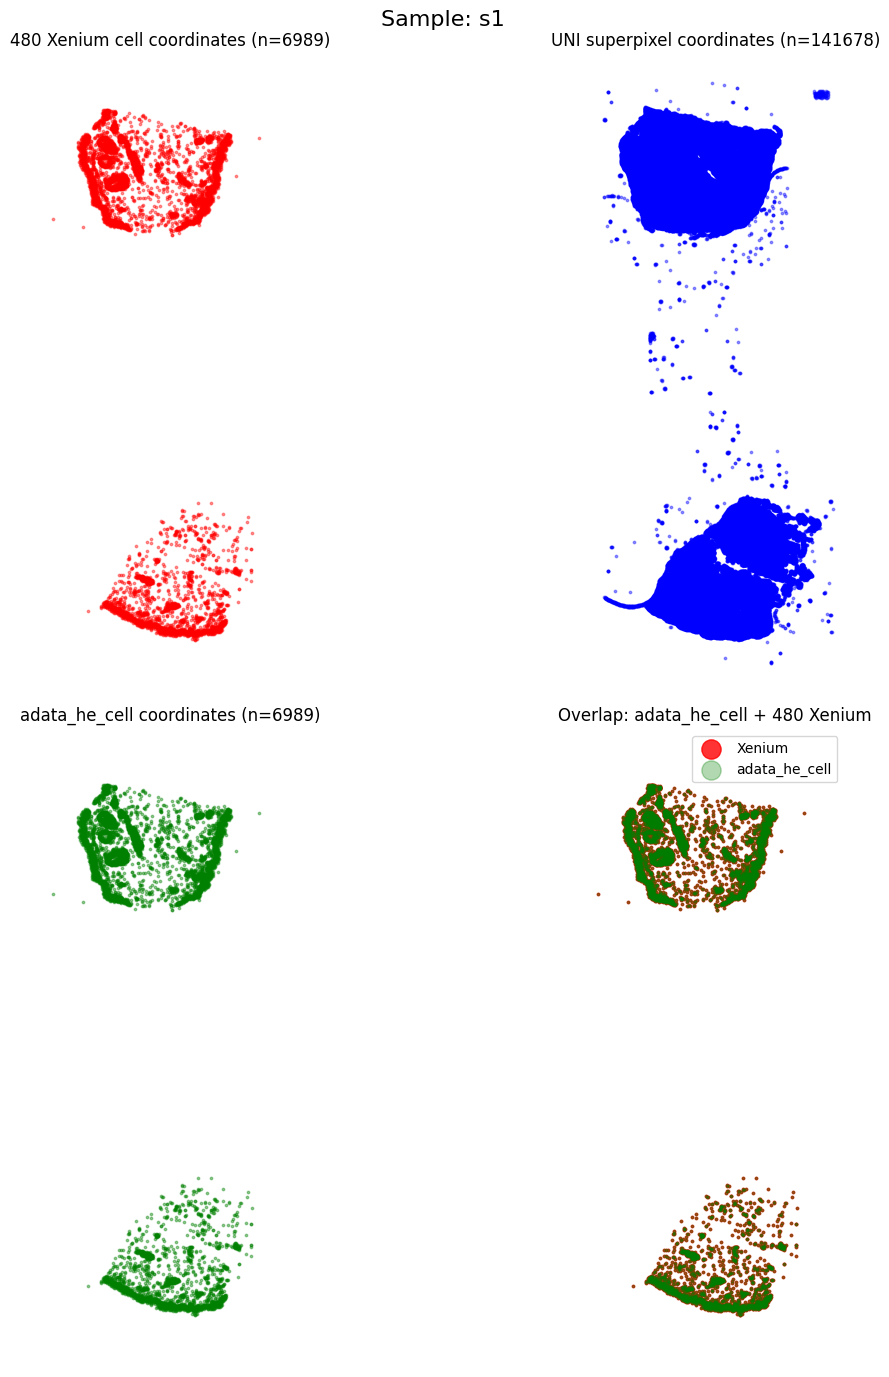


###############################################################################

Sample name: s2


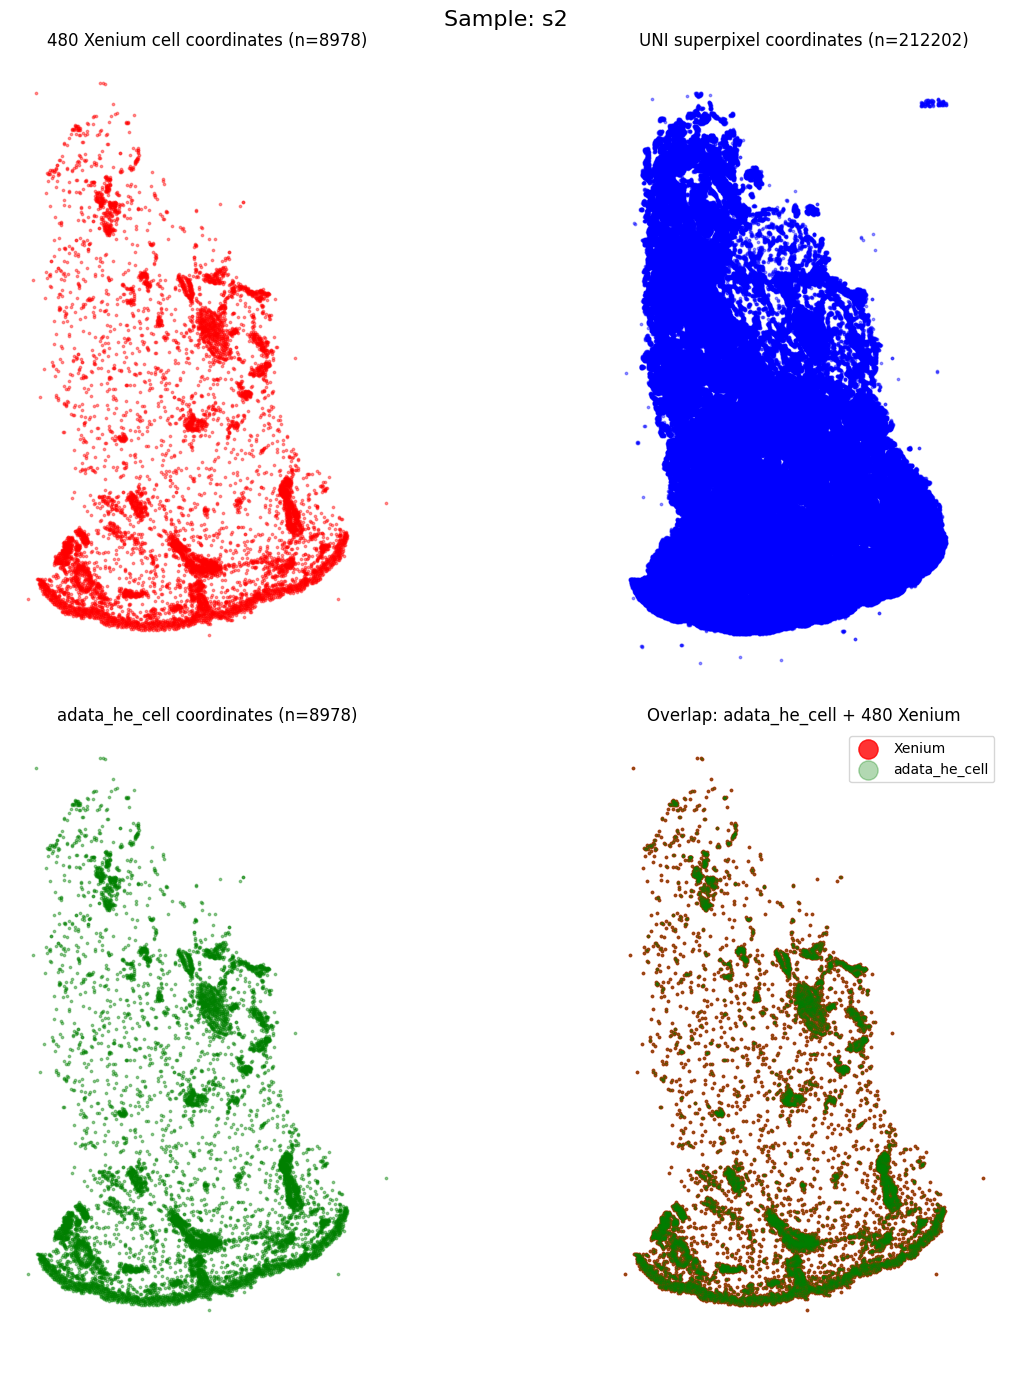


###############################################################################

Sample name: s3


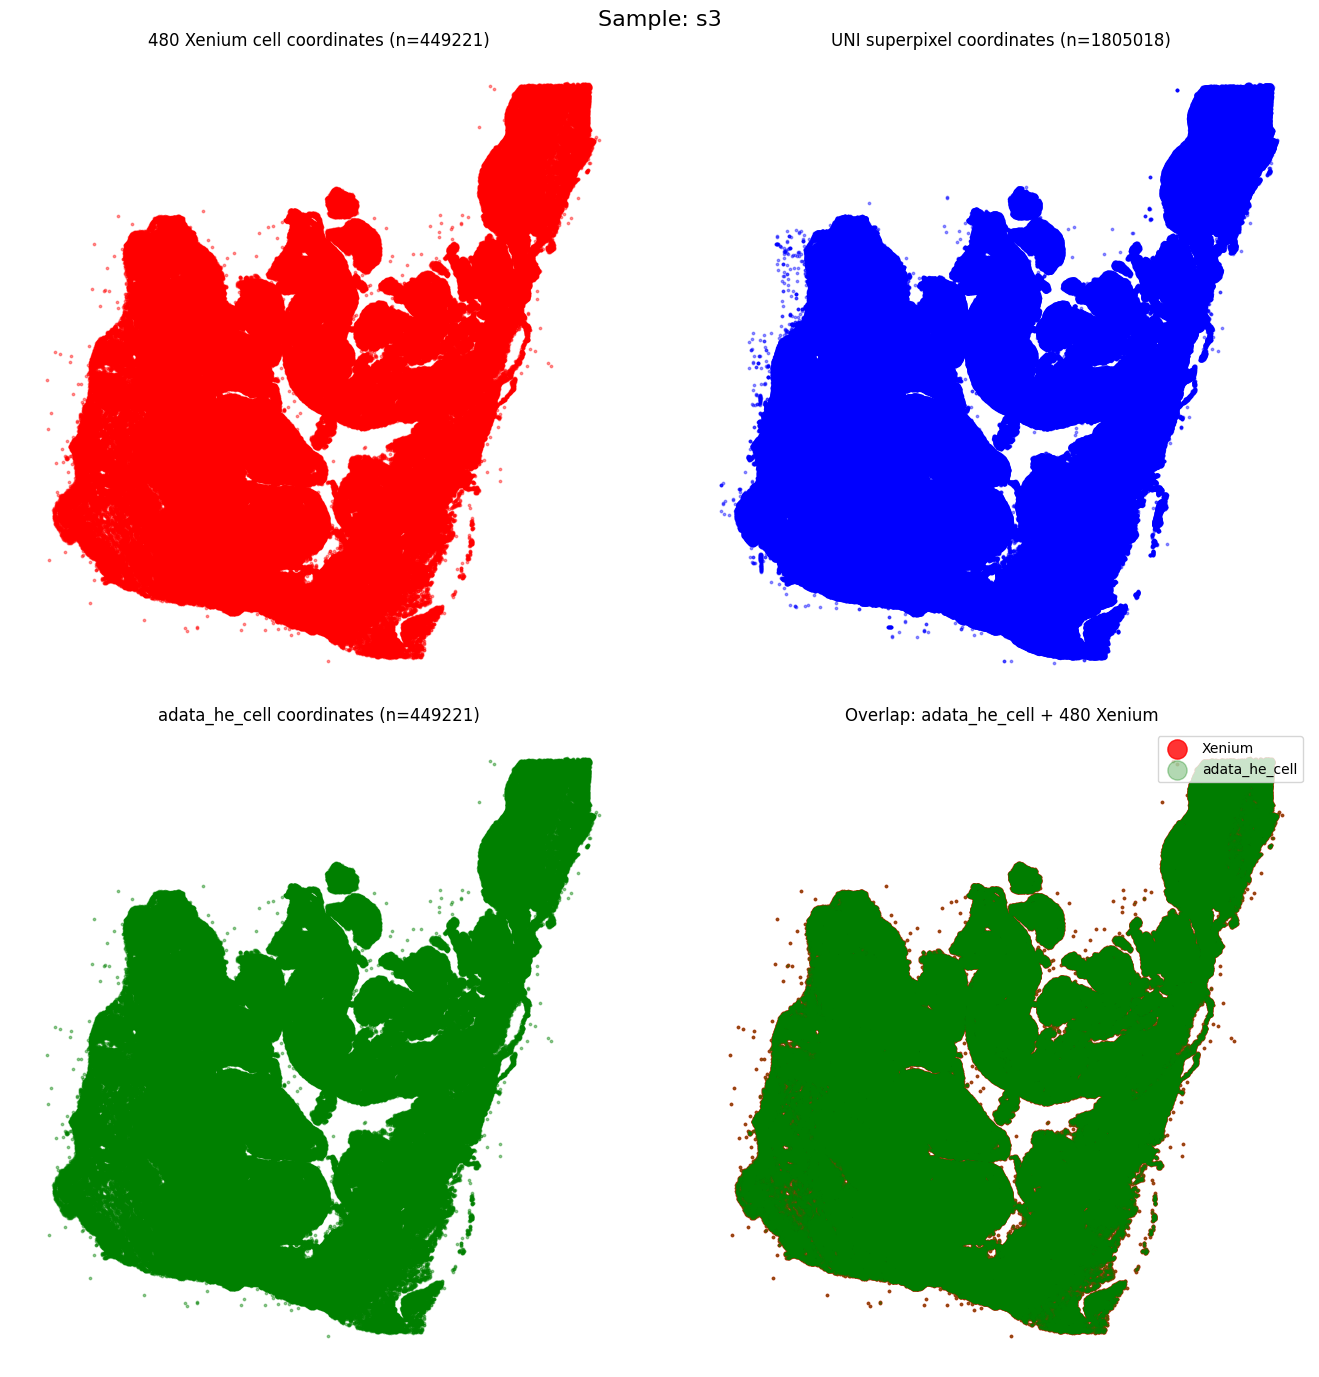


###############################################################################

Sample name: s4


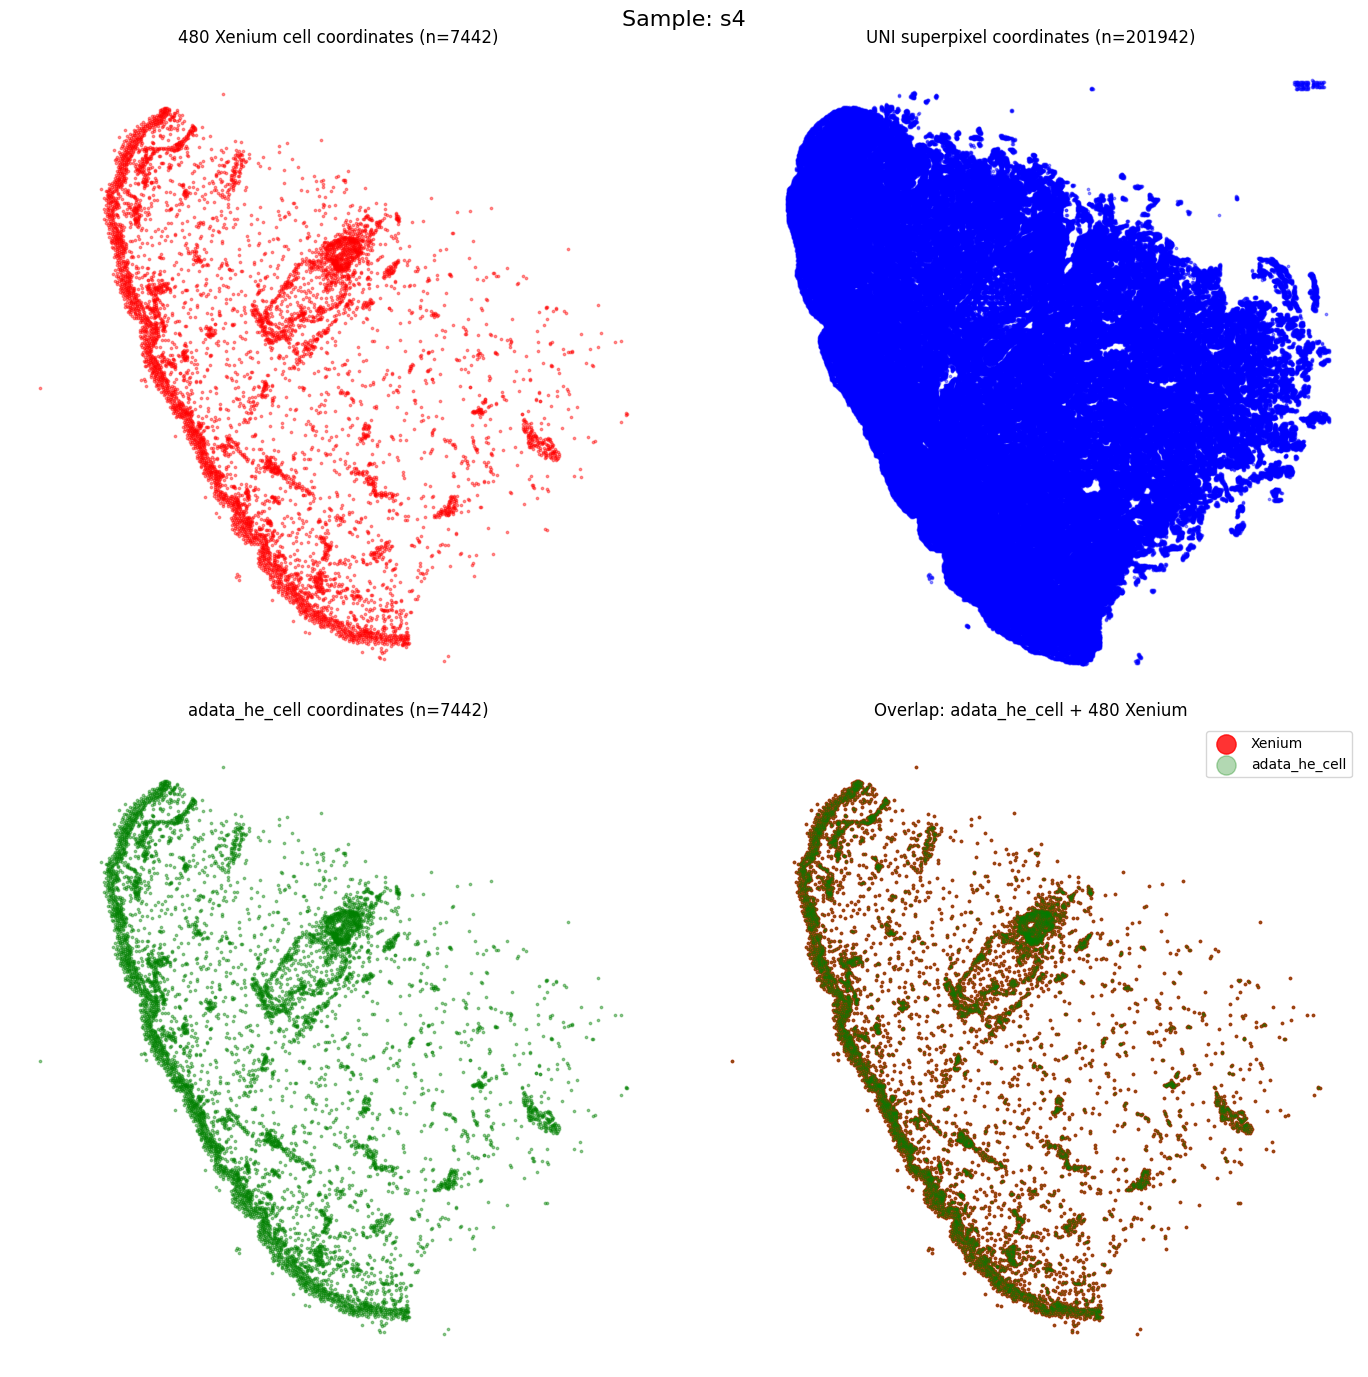


###############################################################################

Sample name: s5


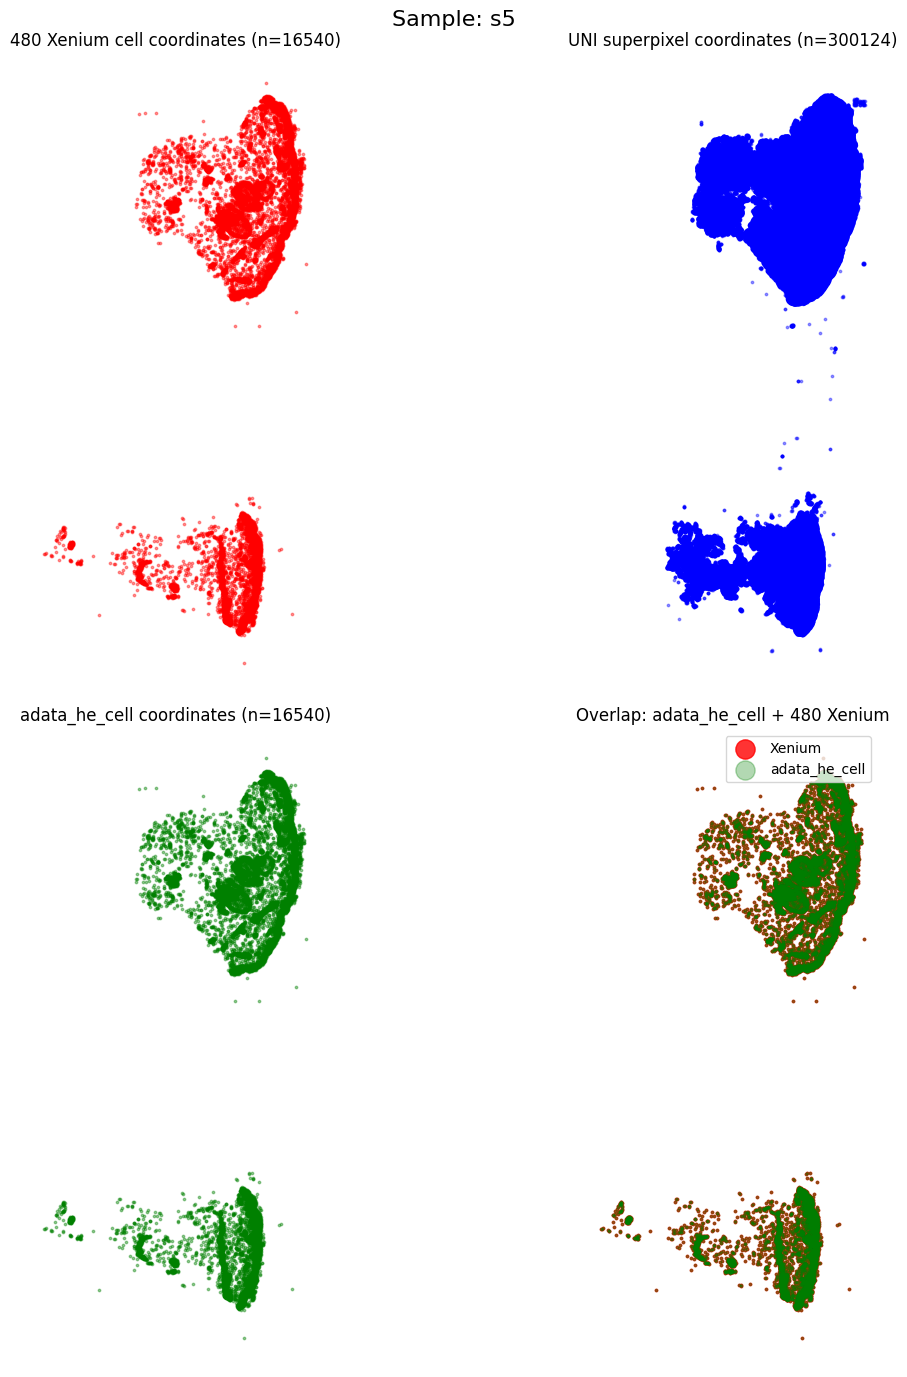


###############################################################################

Sample name: s6


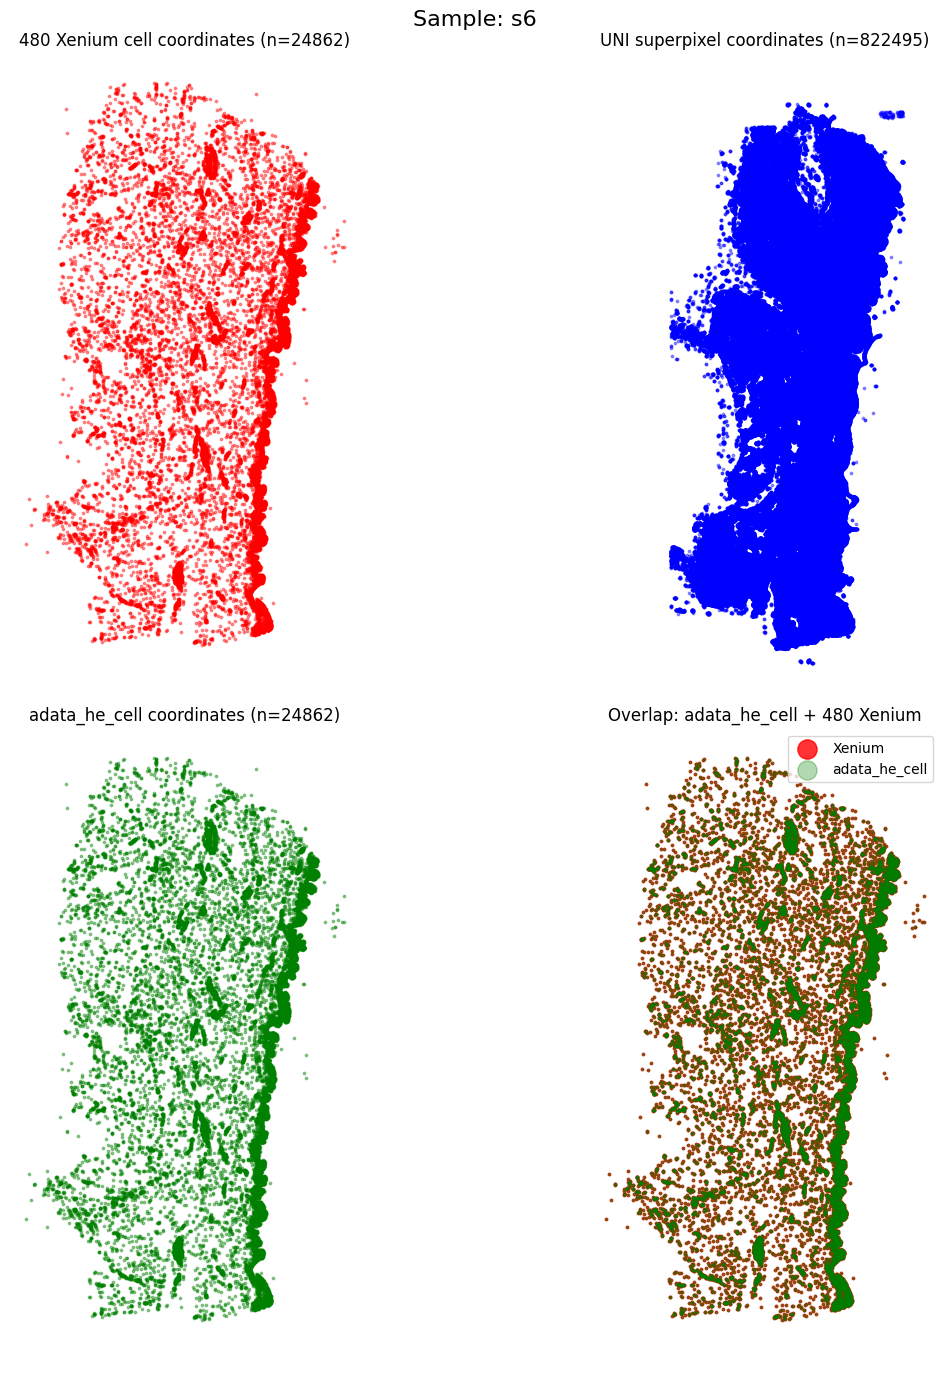

In [33]:

uni_480_list = []
for sample_name, uni_sample_name in panel_480_xenium_to_unifeature_dict.items():
    print()
    print("###############################################################################")
    print()
    print(f"Sample name: {sample_name}")

    ##########################################################################
    # Load UNI features
    adata_he = sc.read(
        CATCH_result_base_dir / "480_panel" / uni_sample_name / "480_panel" / uni_sample_name / "super_pixel_emb.h5ad"
    )
    scale_factor = 16
    adata_he.obsm["spatial"] = adata_he.obsm["spatial"] * scale_factor
    ##########################################################################

    xenium_xy = predicted_rna[sample_name].obsm["spatial"]
    uni_xy = adata_he.obsm["spatial"]

    adata_he_cell = assign_he_features_to_cells(adata_he, xenium_xy)

    # Coordinates for adata_he_cell: use its own spatial if present, else fall back to xenium coords
    if "spatial" in adata_he_cell.obsm:
        assigned_uni_xy = adata_he_cell.obsm["spatial"]
    else:
        assigned_uni_xy = xenium_xy  # cells are 1:1 with Xenium centroids

    plot_coordinate_panels(xenium_xy, uni_xy, assigned_uni_xy, sample_name)

    uni_480_list.append(adata_he_cell)

### Loading 5k


###############################################################################

Sample name: s7


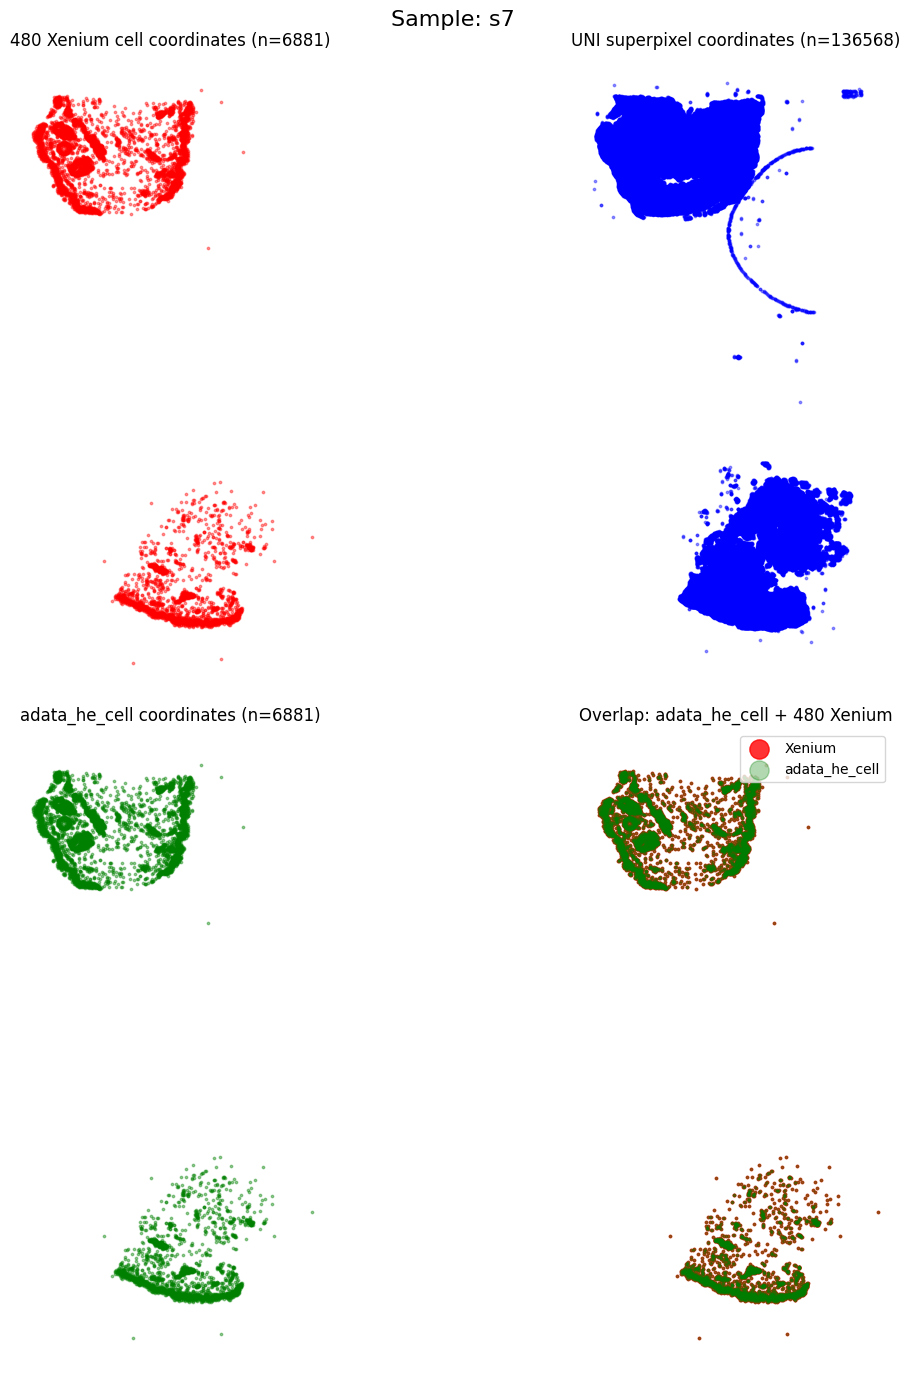


###############################################################################

Sample name: s8


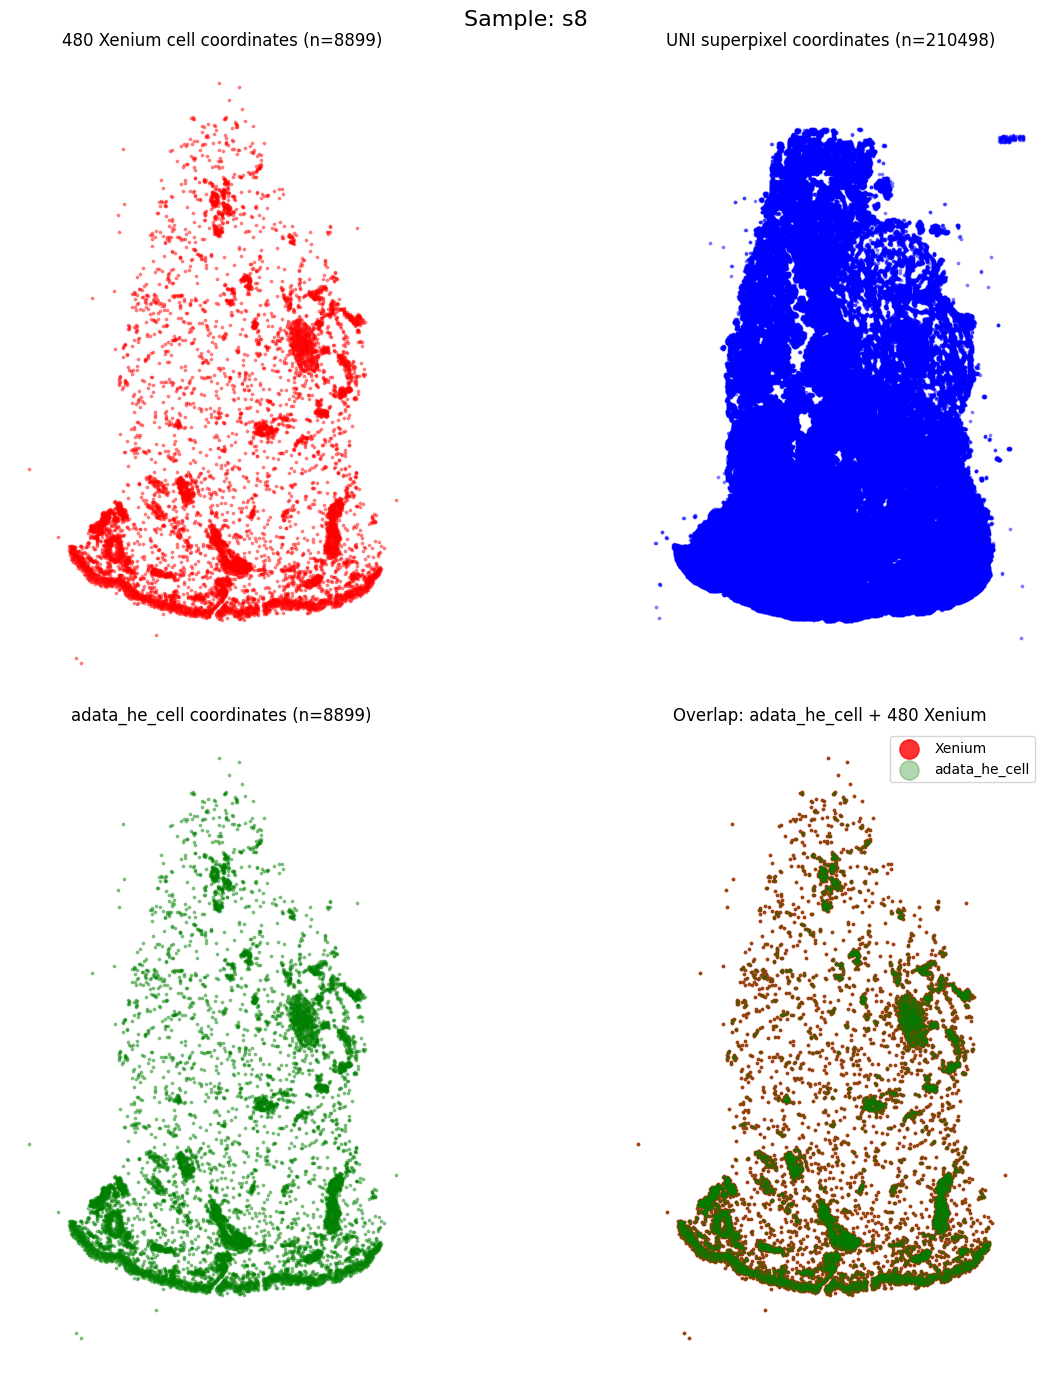


###############################################################################

Sample name: s9


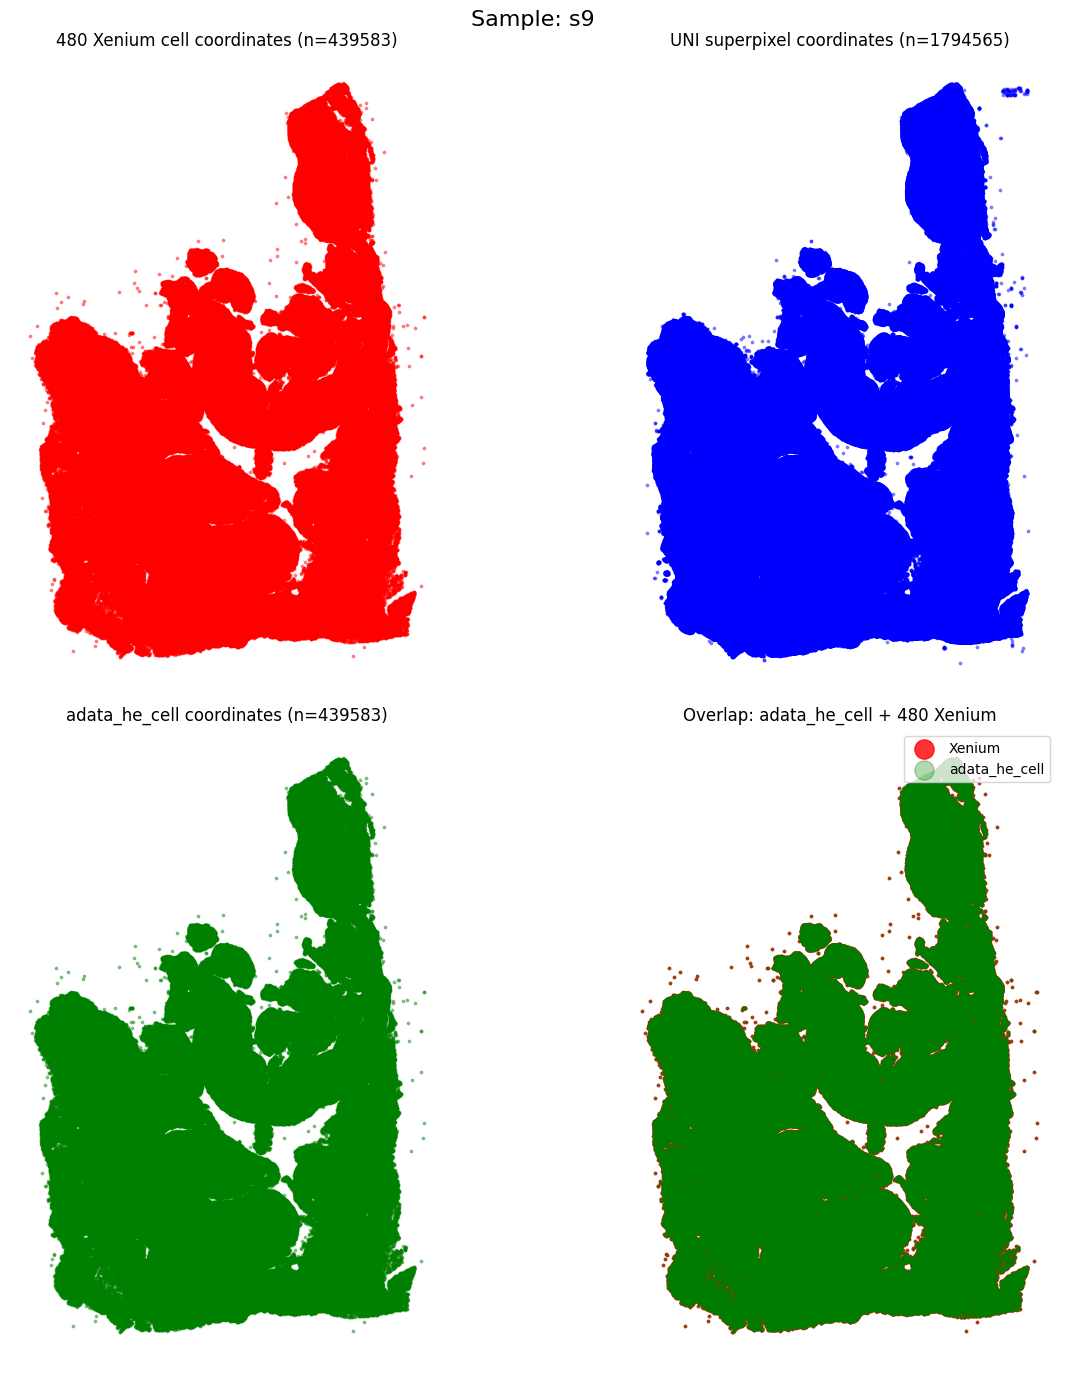


###############################################################################

Sample name: s10


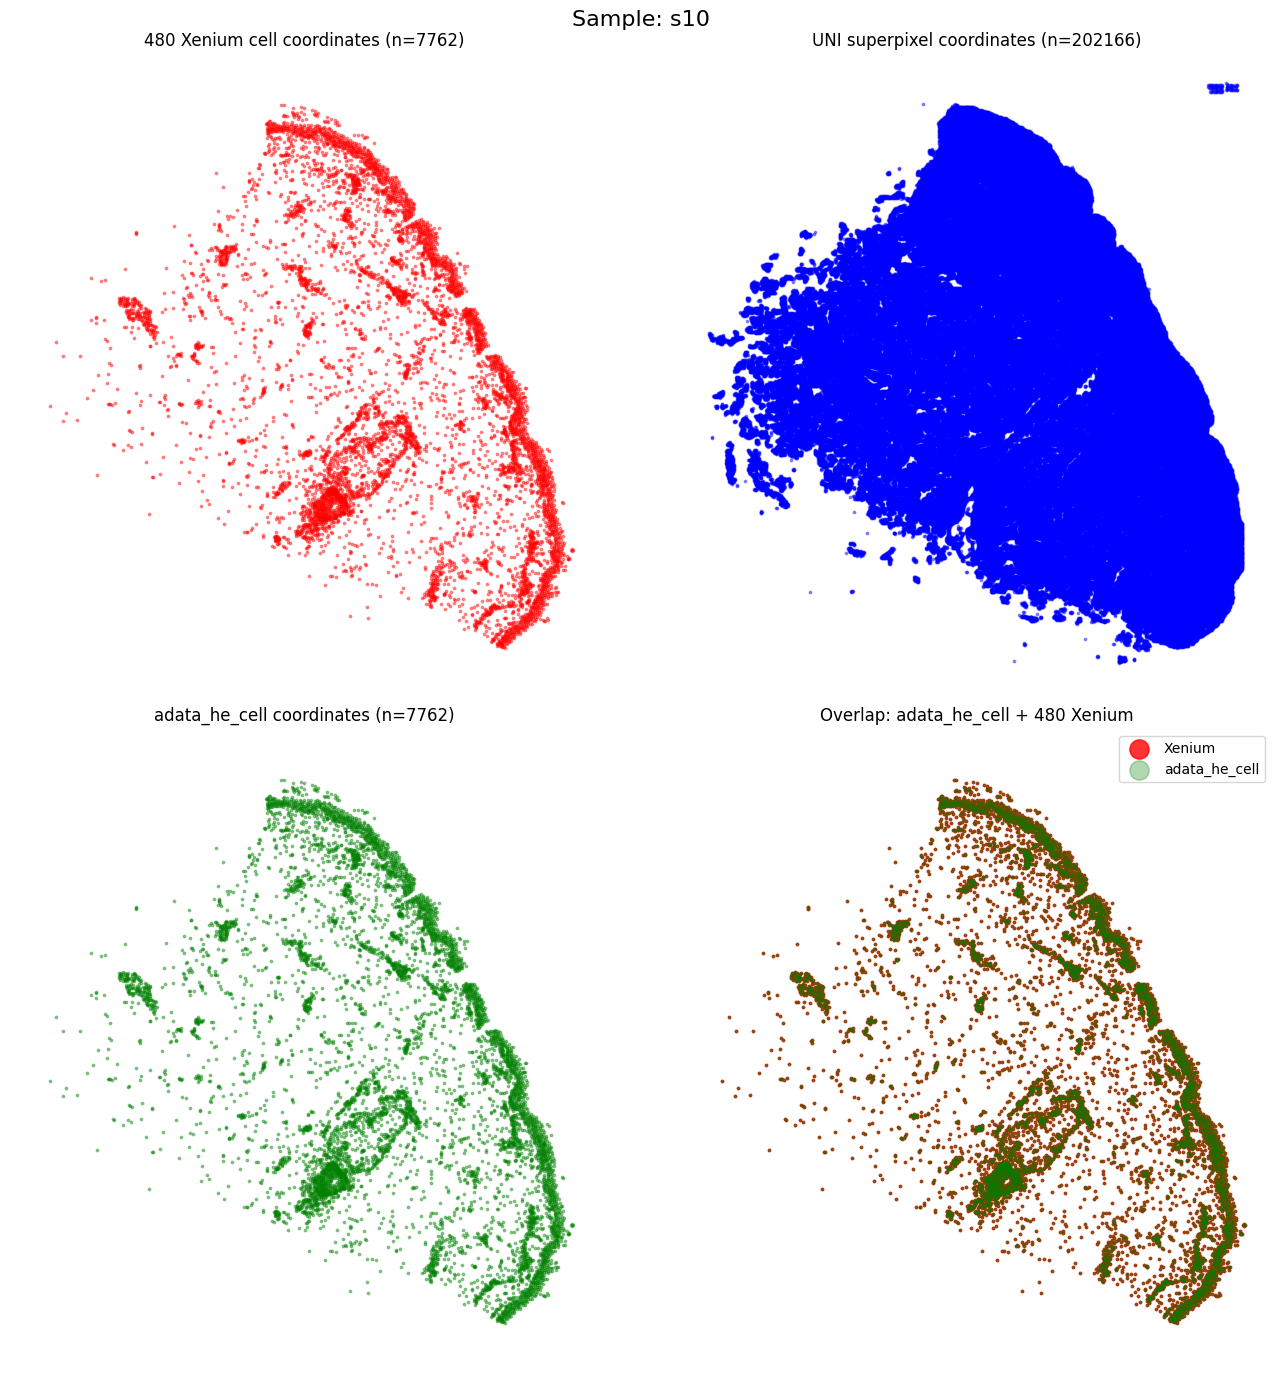


###############################################################################

Sample name: s11


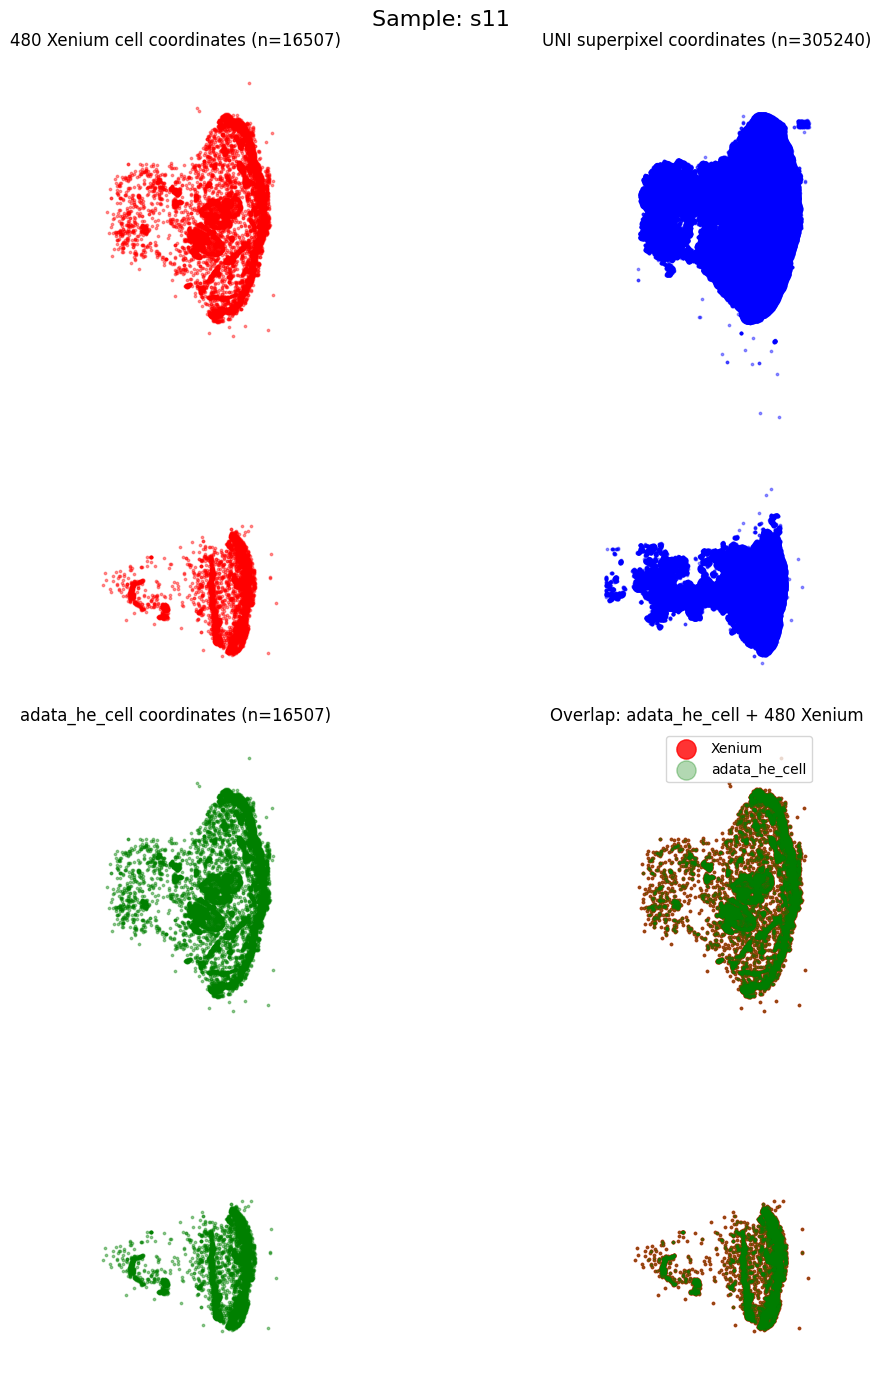


###############################################################################

Sample name: s12


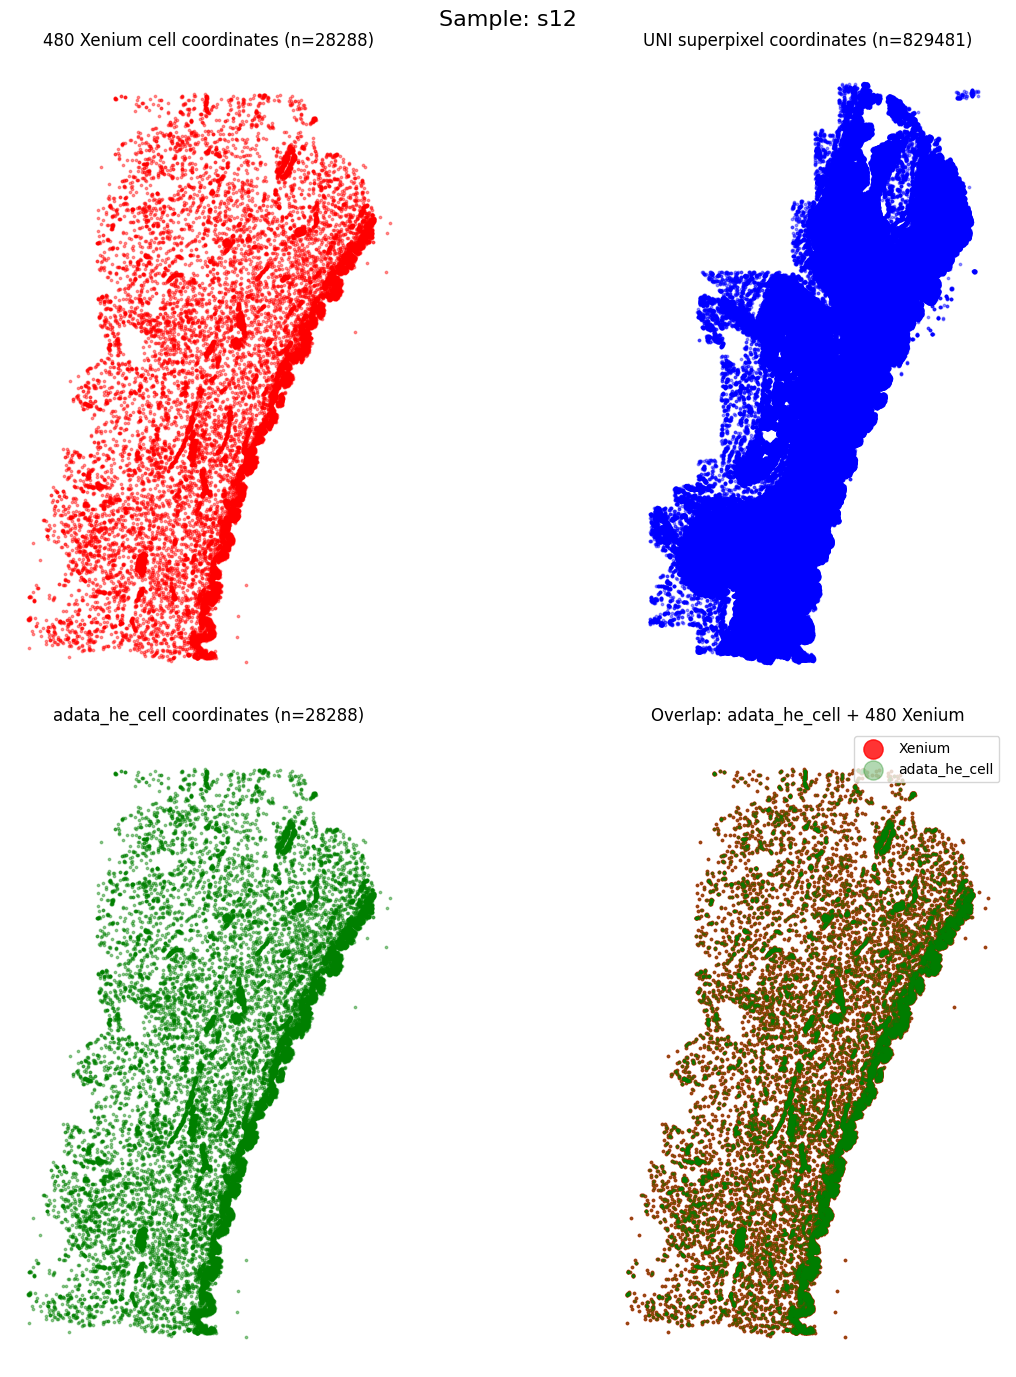

In [34]:

uni_5k_list = []
for sample_name, uni_sample_name in panel_5k_xenium_to_unifeature_dict.items():
    print()
    print("###############################################################################")
    print()
    print(f"Sample name: {sample_name}")

    ##########################################################################
    # Load UNI features
    adata_he = sc.read(
        CATCH_result_base_dir / "5k_panel" / uni_sample_name / "5k_panel" / uni_sample_name / "super_pixel_emb.h5ad"
    )
    scale_factor = 16
    adata_he.obsm["spatial"] = adata_he.obsm["spatial"] * scale_factor
    ##########################################################################

    xenium_xy = predicted_rna[sample_name].obsm["spatial"]
    uni_xy = adata_he.obsm["spatial"]

    adata_he_cell = assign_he_features_to_cells(adata_he, xenium_xy)

    # Coordinates for adata_he_cell: use its own spatial if present, else fall back to xenium coords
    if "spatial" in adata_he_cell.obsm:
        assigned_uni_xy = adata_he_cell.obsm["spatial"]
    else:
        assigned_uni_xy = xenium_xy  # cells are 1:1 with Xenium centroids

    plot_coordinate_panels(xenium_xy, uni_xy, assigned_uni_xy, sample_name)

    uni_5k_list.append(adata_he_cell)

# step 1: automatically align the data. Skip this step if they are aligned in another way

### Align cells using both coarse and fine alignment

In [35]:
from HINGE.automatic_alignment import *

PRE_ALIGNED   = False   # <- set True if externally pre-registered


ICP_TRIM_FRAC = 0.85
ICP_N_ITER    = 100
ICP_TOL       = 1e-7

In [36]:



registration_results = {}

for name_480, name_5k in pairs:
    print(f"\n{'='*58}")
    print(f"  Aligning  {name_5k}  ->  {name_480}")
    print(f"{'='*58}")

    xy_480 = predicted_rna[name_480].obsm['spatial']
    xy_5k  = predicted_rna[name_5k].obsm['spatial']

    xy_5k_registered, A = align_section_pair(
        xy_480, xy_5k,
        pre_aligned=PRE_ALIGNED,
        trim_frac=ICP_TRIM_FRAC,
        n_iter=ICP_N_ITER,
        tol=ICP_TOL,
        pair_label=f"{name_480}/{name_5k}"
    )

    registration_results[(name_480, name_5k)] = {
        'xy_panel2_registered': xy_5k_registered,
        'A': A,
    }

update_coordinates(registration_results, pairs, uni_5k_list, predicted_rna)



  Aligning  s7  ->  s1
[s1/s7] Stage 1/2: Coarse PCA alignment...
    [coarse_align] best flip median dist: 30.07
[s1/s7] Stage 2/2: Robust affine ICP (trim_frac=0.85, n_iter=100)...
    [icp] reached max iterations, median dist (inliers): 17.32
[s1/s7] Registration quality:
    median dist : 20.20 um
    % < 10 um   : 17.4%
    % < 20 um   : 49.5%
    % > 50 um   : 20.5%  <- likely unmatched / tissue boundary

  Aligning  s8  ->  s2
[s2/s8] Stage 1/2: Coarse PCA alignment...
    [coarse_align] best flip median dist: 29.31
[s2/s8] Stage 2/2: Robust affine ICP (trim_frac=0.85, n_iter=100)...
    [icp] reached max iterations, median dist (inliers): 19.36
[s2/s8] Registration quality:
    median dist : 22.75 um
    % < 10 um   : 15.1%
    % < 20 um   : 43.9%
    % > 50 um   : 23.1%  <- likely unmatched / tissue boundary

  Aligning  s9  ->  s3
[s3/s9] Stage 1/2: Coarse PCA alignment...
    [coarse_align] best flip median dist: 16.04
[s3/s9] Stage 2/2: Robust affine ICP (trim_frac=0.85, n

plot_alignment_results(pairs, predicted_rna, registration_results, SAVE_DIR)

In [38]:
uni_5k_list

[AnnData object with n_obs × n_vars = 6881 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 8899 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 439583 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 7762 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 16507 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 28288 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered']

## evaluate coordinates

In [42]:
for pair_idx, (name_480, name_5k) in enumerate(pairs):

    print(f"\n{'='*55}")
    print(f"  Pair: {name_480} / {name_5k}")
    print(f"{'='*55}")

    # ── 480 panel ─────────────────────────────────────────────────
    cell_480_first = predicted_rna[name_480].obsm['spatial'][0]
    uni_480_first  = uni_480_list[pair_idx].obsm['spatial'][0]
    diff_480       = np.abs(cell_480_first - uni_480_first)

    print(f"\n  [{name_480}] 480 panel:")
    print(f"    cell[0] coords : {cell_480_first}")
    print(f"    UNI[0]  coords : {uni_480_first}")
    print(f"    difference     : {diff_480}  →  max={diff_480.max():.6f}")
    print(f"    match          : {'YES' if diff_480.max() < 1e-3 else 'NO'}")

    # ── 5k panel ──────────────────────────────────────────────────
    cell_5k_first = predicted_rna[name_5k].obsm['spatial_registered'][0]
    uni_5k_first  = uni_5k_list[pair_idx].obsm['spatial_registered'][0]
    diff_5k       = np.abs(cell_5k_first - uni_5k_first)

    print(f"\n  [{name_5k}] 5k panel:")
    print(f"    cell[0] coords : {cell_5k_first}")
    print(f"    UNI[0]  coords : {uni_5k_first}")
    print(f"    difference     : {diff_5k}  →  max={diff_5k.max():.6f}")
    print(f"    match          : {' YES' if diff_5k.max() < 1e-3 else 'NO'}")


  Pair: s1 / s7

  [s1] 480 panel:
    cell[0] coords : [ 1754.3195 21392.053 ]
    UNI[0]  coords : [ 1754.3195 21392.053 ]
    difference     : [0. 0.]  →  max=0.000000
    match          : YES

  [s7] 5k panel:
    cell[0] coords : [ 1606.4667692  21499.67549433]
    UNI[0]  coords : [ 1606.4667692  21499.67549433]
    difference     : [0. 0.]  →  max=0.000000
    match          :  YES

  Pair: s2 / s8

  [s2] 480 panel:
    cell[0] coords : [ 1101.946 14436.337]
    UNI[0]  coords : [ 1101.946 14436.337]
    difference     : [0. 0.]  →  max=0.000000
    match          : YES

  [s8] 5k panel:
    cell[0] coords : [ 2537.44684732 14433.65449844]
    UNI[0]  coords : [ 2537.44684732 14433.65449844]
    difference     : [0. 0.]  →  max=0.000000
    match          :  YES

  Pair: s3 / s9

  [s3] 480 panel:
    cell[0] coords : [30949.604 36046.06 ]
    UNI[0]  coords : [30949.604 36046.06 ]
    difference     : [0. 0.]  →  max=0.000000
    match          : YES

  [s9] 5k panel:
    cel

## save checkpoint

In [43]:


sample_names_panel1 = ['s1', 's2', 's3', 's4', 's5', 's6']
sample_names_panel2 = ['s7', 's8', 's9', 's10', 's11', 's12']

save_dict = {
    'RNA_panel1'           : {name: predicted_rna[name] for name in sample_names_panel1},
    'RNA_panel2'           : {name: predicted_rna[name] for name in sample_names_panel2},
    'HE_panel1'            : uni_480_list,
    'HE_panel2'            : uni_5k_list
}

with open(SAVE_DIR / 'checkpoint_step1.pkl', 'wb') as f:
    pickle.dump(save_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

# Step 2: extract

In [49]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
from HINGE.feature_mapping import *


In [70]:
n_pca_comps = 256
n_gene_comps = 128

In [71]:
with open(SAVE_DIR / 'checkpoint_step1.pkl', "rb") as f:
    data_dict=pickle.load(f)

data_dict

{'RNA_panel1': {'s1': AnnData object with n_obs × n_vars = 6989 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's2': AnnData object with n_obs × n_vars = 8978 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's3': AnnData object with n_obs × n_vars = 449221 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's4': AnnData object with n_obs × n_vars = 7442 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's5': AnnData object with n_obs × n_vars = 16540 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'f

In [72]:
#select which sample to use for the mapping

uni_480_list = data_dict['HE_panel1'][0:2]  # only the first sample for demonstration
uni_5k_list = data_dict['HE_panel2'][0:2]  # only the first sample for demonstration
rna_480_list = [data_dict['RNA_panel1']['s1'], data_dict['RNA_panel1']['s2']]  # only the first sample for demonstration
rna_5k_list = [data_dict['RNA_panel2']['s7'],data_dict['RNA_panel2']['s8'] ]  # only the first sample for demonstration

In [73]:
uni_480_list

[AnnData object with n_obs × n_vars = 6989 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 8978 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial']

In [74]:
uni_5k_list

[AnnData object with n_obs × n_vars = 6881 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 8899 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial', 'spatial_registered']

In [75]:
rna_480_list

[AnnData object with n_obs × n_vars = 6989 × 5101
     obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial',
 AnnData object with n_obs × n_vars = 8978 × 5101
     obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial']

In [76]:
rna_5k_list

[AnnData object with n_obs × n_vars = 6881 × 480
     obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial', 'spatial_registered',
 AnnData object with n_obs × n_vars = 8899 × 480
     obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
     var: 'gene_ids', 'feature_types', 'genome'
     obsm: 'spatial', 'spatial_registered']

In [77]:
'''
def plot_pca_variance_curve(uni_panel1_list, uni_panel2_list,
                             max_comps=200):
    """
    Plot cumulative variance explained vs n_components.
    Helps choose the right n_pca_comps.
    """
    all_X = []
    for adata in uni_panel1_list + uni_panel2_list:
        X = adata.X.toarray() if issparse(adata.X) else np.array(adata.X)
        all_X.append(X.astype(np.float32))
    all_X = np.vstack(all_X)

    n_comps = min(max_comps, all_X.shape[1] - 1, all_X.shape[0] - 1)
    pca     = PCA(n_components=n_comps, random_state=42)
    pca.fit(all_X)

    cumvar = np.cumsum(pca.explained_variance_ratio_)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Cumulative variance
    axes[0].plot(range(1, n_comps + 1), cumvar, linewidth=2)
    for threshold in [0.80, 0.90, 0.95]:
        n_needed = np.searchsorted(cumvar, threshold) + 1
        axes[0].axhline(threshold, color='gray', linestyle='--', alpha=0.5)
        axes[0].axvline(n_needed,  color='gray', linestyle='--', alpha=0.5)
        axes[0].text(n_needed + 2, threshold - 0.01,
                     f'{threshold:.0%} @ {n_needed} comps',
                     fontsize=8, color='gray')
    axes[0].axvline(64, color='red', linestyle='-', linewidth=1.5,
                    label='current (64 comps)')
    axes[0].set_xlabel('Number of components')
    axes[0].set_ylabel('Cumulative variance explained')
    axes[0].set_title('PCA Variance Curve — UNI features')
    axes[0].legend(fontsize=9)
    axes[0].grid(alpha=0.3)

    # Per-component variance (elbow plot)
    axes[1].plot(range(1, min(100, n_comps) + 1),
                 pca.explained_variance_ratio_[:100] * 100,
                 linewidth=2)
    axes[1].axvline(64, color='red', linestyle='-', linewidth=1.5,
                    label='current (64 comps)')
    axes[1].set_xlabel('Component')
    axes[1].set_ylabel('Variance explained (%)')
    axes[1].set_title('Per-component Variance (first 100)')
    axes[1].legend(fontsize=9)
    axes[1].grid(alpha=0.3)

    # Print summary
    for threshold in [0.70, 0.80, 0.90, 0.95]:
        n_needed = np.searchsorted(cumvar, threshold) + 1
        print(f"  {threshold:.0%} variance retained: {n_needed} components")

    plt.tight_layout()

    plt.show()

    return pca, cumvar

pca_diagnostic, cumvar = plot_pca_variance_curve(
     data_dict['HE_panel1'][0:2],  data_dict['HE_panel2'][0:2], max_comps=1048
)

'''

'\ndef plot_pca_variance_curve(uni_panel1_list, uni_panel2_list,\n                             max_comps=200):\n    """\n    Plot cumulative variance explained vs n_components.\n    Helps choose the right n_pca_comps.\n    """\n    all_X = []\n    for adata in uni_panel1_list + uni_panel2_list:\n        X = adata.X.toarray() if issparse(adata.X) else np.array(adata.X)\n        all_X.append(X.astype(np.float32))\n    all_X = np.vstack(all_X)\n\n    n_comps = min(max_comps, all_X.shape[1] - 1, all_X.shape[0] - 1)\n    pca     = PCA(n_components=n_comps, random_state=42)\n    pca.fit(all_X)\n\n    cumvar = np.cumsum(pca.explained_variance_ratio_)\n\n    fig, axes = plt.subplots(1, 2, figsize=(12, 4))\n\n    # Cumulative variance\n    axes[0].plot(range(1, n_comps + 1), cumvar, linewidth=2)\n    for threshold in [0.80, 0.90, 0.95]:\n        n_needed = np.searchsorted(cumvar, threshold) + 1\n        axes[0].axhline(threshold, color=\'gray\', linestyle=\'--\', alpha=0.5)\n        axes[0].axv

In [78]:



# ── Prepare features ──────────────────────────────────────────────────────
morph_480_list, morph_5k_list, morph_pca = prepare_morphology_features(
    uni_480_list, uni_5k_list, n_pca_comps=n_pca_comps
)


  Preparing morphology features (UNI embeddings)
combining UNI features from both panels...
  Fitting PCA on (31747, 2048) UNI features → 128 components...
  Variance retained: 70.8%
panel 1 morph (6989, 128), panel 2 morph (6881, 128)
panel 1 morph (8978, 128), panel 2 morph (8899, 128)


In [79]:
morph_480_list

[array([[-0.42224535,  0.14513147, -0.25961277, ...,  0.02093948,
          0.03966614,  0.08906619],
        [-0.32110602,  0.28465733, -0.04458773, ...,  0.02731491,
         -0.05868226,  0.05124918],
        [-0.34736943,  0.27405557, -0.12656772, ...,  0.03655283,
          0.0041967 ,  0.02097519],
        ...,
        [ 0.33208027, -0.48703316, -0.09190693, ...,  0.03513044,
          0.03332579, -0.03672107],
        [ 0.39293835, -0.44408318,  0.02612782, ...,  0.02866885,
          0.07392756,  0.02764333],
        [ 0.4249467 , -0.45248872,  0.11121456, ...,  0.00946607,
          0.01688831, -0.04947094]], dtype=float32),
 array([[ 0.21750848, -0.2708816 , -0.29657868, ..., -0.06371786,
          0.024606  ,  0.05059587],
        [ 0.36921358, -0.09379119, -0.3207833 , ...,  0.04431367,
         -0.06762876, -0.00976002],
        [ 0.36212364, -0.07499253, -0.3463438 , ..., -0.00135178,
         -0.00739321, -0.04380706],
        ...,
        [ 0.10266194, -0.02640261, -0.2

In [80]:
morph_5k_list

[array([[-0.46696657, -0.36762136, -0.20882003, ...,  0.04749651,
          0.00812622, -0.04521677],
        [-0.5146651 , -0.07610715, -0.19805345, ...,  0.01826836,
         -0.03067152, -0.03655104],
        [-0.5280992 , -0.140149  , -0.10949028, ..., -0.02588534,
         -0.00653143, -0.05634837],
        ...,
        [ 0.39917785, -0.45368692,  0.20568965, ...,  0.0090708 ,
         -0.03788633, -0.01248463],
        [ 0.39917785, -0.45368692,  0.20568965, ...,  0.0090708 ,
         -0.03788633, -0.01248463],
        [ 0.4163    , -0.42777243,  0.18642275, ...,  0.02714869,
          0.05131054, -0.0458566 ]], dtype=float32),
 array([[ 0.31408465, -0.27851167, -0.17063373, ...,  0.04025264,
         -0.02883256, -0.00128027],
        [ 0.32297516, -0.07180803,  0.03168666, ..., -0.00796019,
         -0.10482079, -0.07829608],
        [ 0.40414223, -0.23042779,  0.09929845, ..., -0.0791937 ,
         -0.10411891, -0.01527098],
        ...,
        [-0.08910433, -0.465152  ,  0.0

In [81]:

expr_480_list, expr_5k_list, expr_pca, overlap_genes = prepare_expression_features(
    rna_480_list,rna_5k_list, n_comps=n_gene_comps
)


  Preparing expression features (overlapping genes PCA)
  Overlapping genes across all samples: 444
  Fitting expression PCA on (15967, 444) → 128 components...
  Variance retained: 97.3%
Panel 1 expr (6989, 128), Panel 2 expr (6989, 128)
Panel 1 expr (8978, 128), Panel 2 expr (8978, 128)


In [82]:
step2_save_dict = {
    'RNA_extracted_panel1'           : expr_480_list,
    'RNA_extracted_panel2'           : expr_5k_list,
    'HE_extracted_panel1'            : morph_480_list,
    'HE_extracted_panel2'            : morph_5k_list,
    'RNA_panel1'                     :rna_480_list ,
    "RNA_panel2"                     :rna_5k_list
}
SAVE_DIR = Path('./hinge_checkpoints')
SAVE_DIR.mkdir(exist_ok=True)
with open(SAVE_DIR / 'checkpoint_step2.pkl', 'wb') as f:
    pickle.dump(step2_save_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

# Step 3:match

In [83]:
from HINGE.evaluation import *
from HINGE.matching_with_global_assignment import *

In [84]:


# ── Config ────────────────────────────────────────────────────────────────
CELLTYPE_COL  = 'cell_type'   # ← adjust to your obs column name
MAX_DIST      = 30           # μm — spatial search radius
K_CANDIDATES  = 20             # spatial candidates per cell
K_NEIGHBORS   = 5             # neighborhood size for consistency


STRATEGY_LABELS = {
    'A_distance'  : 'Distance\nonly',
    'B_histology' : 'Histology\nonly',
    'C_expression': 'Expression\nonly',
    'D_combined'  : 'Histology +\nExpression',
}
STRATEGY_COLORS = {
    'A_distance'  : '#95a5a6',
    'B_histology' : '#3498db',
    'C_expression': '#2ecc71',
    'D_combined'  : '#e74c3c',
}


In [85]:
with open(SAVE_DIR / 'checkpoint_step2.pkl', "rb") as f:
    data_dict=pickle.load(f)

{'RNA_extracted_panel1': [array([[ 0.89643769, -0.11992059, -0.22113062, ..., -0.02501518,
          -0.01166487, -0.00188235],
         [ 0.93911858, -0.14376871, -0.01149191, ..., -0.00416783,
           0.00536384,  0.00745656],
         [ 0.9096958 , -0.20940593, -0.07151194, ..., -0.00752497,
           0.00990502,  0.00692627],
         ...,
         [-0.57208161,  0.44704457,  0.02758448, ..., -0.01766864,
           0.01597791, -0.02427791],
         [-0.59517211,  0.05043237,  0.17960426, ...,  0.00260486,
          -0.02541131,  0.02745201],
         [-0.83824627, -0.16576142,  0.33653598, ...,  0.01167552,
          -0.02351708, -0.02745068]]),
  array([[-6.67927703e-01,  3.94498005e-01, -1.12339028e-01, ...,
          -3.68618633e-02,  5.15296074e-03,  1.93823421e-02],
         [-3.43227945e-01,  6.92714130e-01, -3.49449132e-01, ...,
          -3.23200317e-02, -9.95034497e-03,  3.78481127e-03],
         [-3.17496699e-01,  7.27464685e-01, -3.37307253e-01, ...,
          -9.6

In [86]:


# ── Run matching + evaluation for all pairs ───────────────────────────────
strategies       = list(STRATEGY_LABELS.keys())
all_eval_scores  = {s: [] for s in strategies}   # pooled across all pairs
per_pair_scores  = {}                             # per pair breakdown

for idx in range(data_dict['RNA_extracted_panel1'].__len__()):
    print(f"\n{'='*58}")
    print(f"  Processing pair {idx+1}")
    print(f"{'='*58}")

    xy_panel1    = data_dict['RNA_panel1'][idx].obsm['spatial']
    xy_panel2_reg = data_dict['RNA_panel2'][idx].obsm['spatial_registered']

    # Run all matching strategies
    match_results = run_all_strategies(
        xy_panel1       = xy_panel1,
        xy_panel2_reg   = xy_panel2_reg,
        morph_panel1    = data_dict['HE_extracted_panel1'][idx],
        morph_panel2     = data_dict['HE_extracted_panel2'][idx],
        expr_panel1     = data_dict["RNA_extracted_panel1"][idx],
        expr_panel2      = data_dict["RNA_extracted_panel2"][idx],
        max_dist     = MAX_DIST,
        k_candidates = K_CANDIDATES
    )




    # Evaluate each strategy

    per_pair_scores[idx] = {}
    print(f"\n  Evaluating neighborhood consistency ({CELLTYPE_COL})...")

    for strategy, (idx_480, idx_5k) in match_results.items():
        scores = compute_neighborhood_consistency(
            xy_panel1       = xy_panel1,
            xy_panel2_reg    = xy_panel2_reg,
            idx_panel1      = idx_480,
            idx_panel2       = idx_5k,
            adata_panel1    = data_dict["RNA_panel1"][idx],
            adata_panel2     = data_dict["RNA_panel2"][idx],
            k_neighbors  = K_NEIGHBORS,
            celltype_col = CELLTYPE_COL
        )
        per_pair_scores[idx][strategy] = scores
        all_eval_scores[strategy].extend(scores.tolist())
        print(f"  {STRATEGY_LABELS[strategy].replace(chr(10),' '):<25} "
                      f"median = {np.median(scores):.4f}  (n={len(scores)})",
                      f"mean = {np.mean(scores):.4f}  (n={len(scores)})")
        





  Processing pair 1

  ---  ---
  [A distance   ]   4283 pairs (61.3%), median dist = 15.42
  [B histology  ]   4637 pairs (66.3%), median dist = 37.53, median sim = 0.491
  [C expression ]   4121 pairs (59.0%), median dist = 38.38, median sim = 0.563
  [D combined   ]   4513 pairs (64.6%), median dist = 37.85, median sim = 0.480

  Evaluating neighborhood consistency (cell_type)...
  Distance only             median = 0.9893  (n=4283)
  Histology only            median = 0.9941  (n=4637)
  Expression only           median = 0.9941  (n=4121)
  Histology + Expression    median = 0.9941  (n=4513)

  Processing pair 2

  ---  ---
  [A distance   ]   5639 pairs (62.8%), median dist = 17.09
  [B histology  ]   6053 pairs (67.4%), median dist = 35.38, median sim = 0.511
  [C expression ]   4906 pairs (54.6%), median dist = 37.13, median sim = 0.530
  [D combined   ]   5808 pairs (64.7%), median dist = 35.22, median sim = 0.447

  Evaluating neighborhood consistency (cell_type)...
  Distance

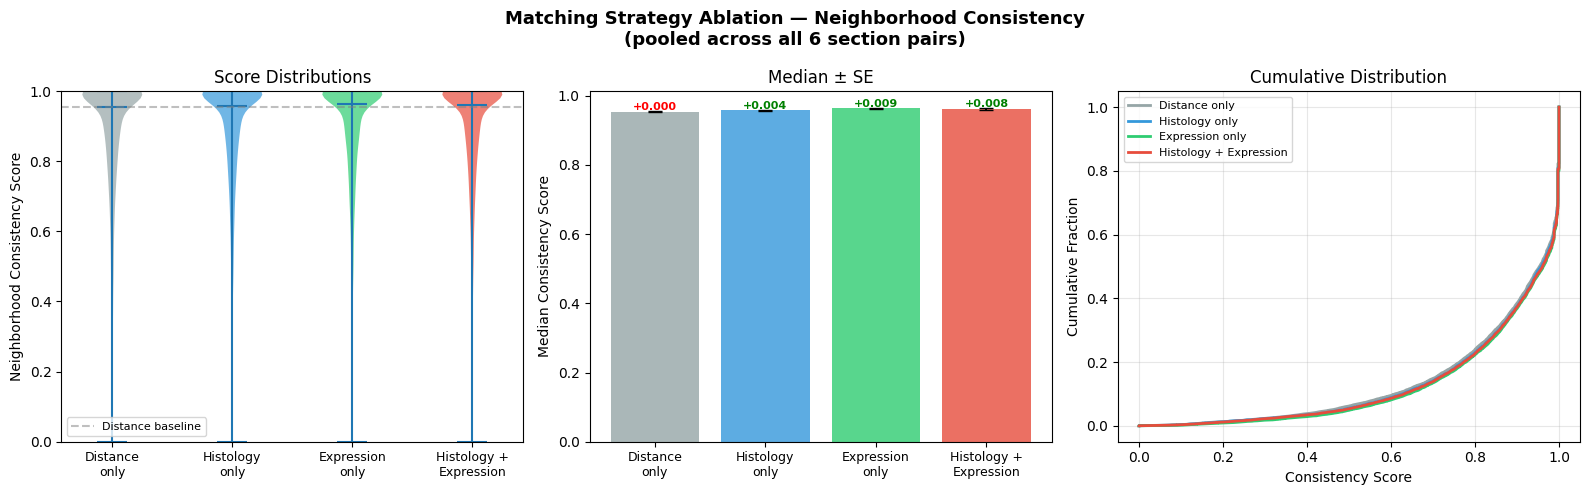

In [87]:
# ── Visualize ─────────────────────────────────────────────────────────────
plot_ablation_summary(all_eval_scores)

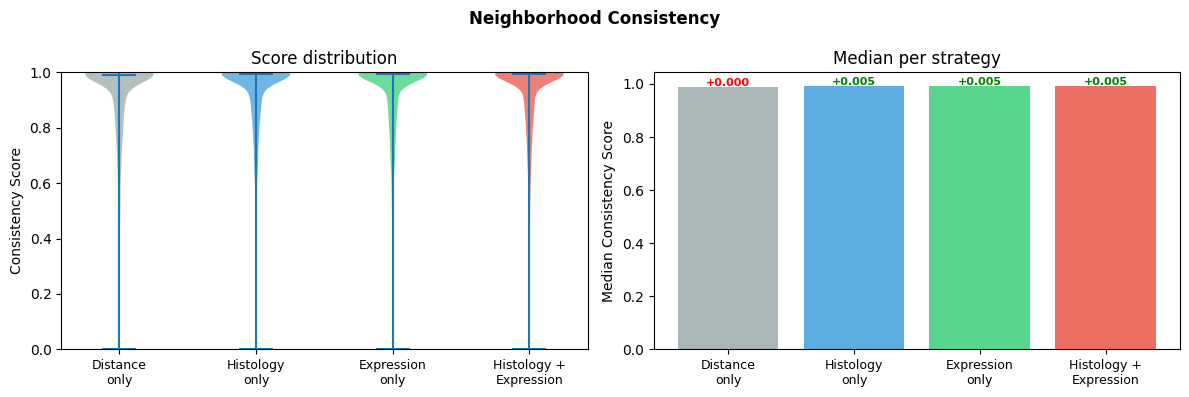

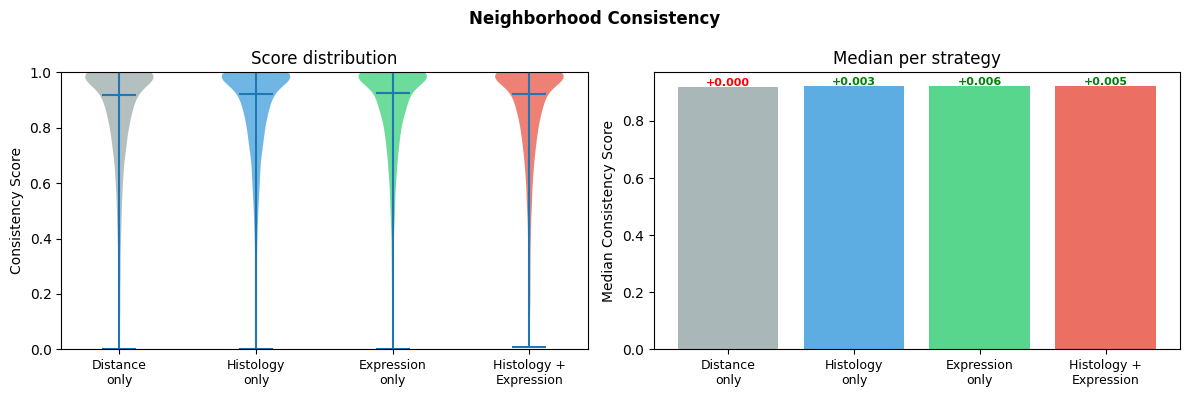

In [88]:
plot_ablation_per_pair(per_pair_scores)